# Практическое задание 1. Исследовательский анализ данных и линейная регрессия.

В этом задании вы научитесь анализировать данные и выделять из них полезные признаки.

**Обратите внимание**, что для выполнения данного задания необходимо подключения к картографическому серверу openstreetmap. В классе такого подключения нет, поэтому, **пожалуйста**, делайте дома необходимые **скриншоты**, чтобы вашу работу можно было увидеть в классе.

В этом ноутбуке используется библиотека `folium` для визуализации карт.

Если вы всё сделали правильно, то выше должна открыться карта Москвы.

In [1]:
#Поменять признак где участвует скорость и убрать пояснения сделанные GPT под всеми графиками

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set(style="darkgrid")

## Часть 0. Подготовка (1 балл)

**Задание 1**. Мы будем работать с данными из соревнования `New York City Taxi Trip Duration`

**Путь к данным:** 
- `data\nyc-taxi-trip-duration\train.csv`
- `data\nyc-taxi-trip-duration\test.csv`

In [3]:
# ВАШ КОД
train_data = pd.read_csv('nyc_taxi_trip/train.csv')

In [4]:
train_data.head()


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


Обратите внимание на колонки `pickup_datetime` и `dropoff_datetime`. `dropoff_datetime` был добавлена организаторами только в обучающую выборку, то есть использовать эту колонку нельзя, давайте удалим ее. В `pickup_datetime` записаны дата и время начала поездки. Чтобы с ней было удобно работать, давайте преобразуем даты в `datetime`-объекты

In [5]:
# ВАШ КОД
train_data = train_data.drop('dropoff_datetime', axis = 1)

In [6]:
train_data['pickup_datetime'] = pd.to_datetime(train_data['pickup_datetime'])

В колонке `trip_duration` записано целевое значение, которое мы хотим предсказывать. Давайте посмотрим на распределение таргета в обучающей выборке. Для этого нарисуйте его гистограмму:

In [7]:
trip_duration = train_data['trip_duration']

In [8]:
train_data['trip_duration'].mean()

np.float64(959.4922729603659)

In [9]:
train_data['trip_duration'].std()

np.float64(5237.431724497621)

In [10]:
mask = train_data['trip_duration']<train_data['trip_duration'].quantile(0.99)

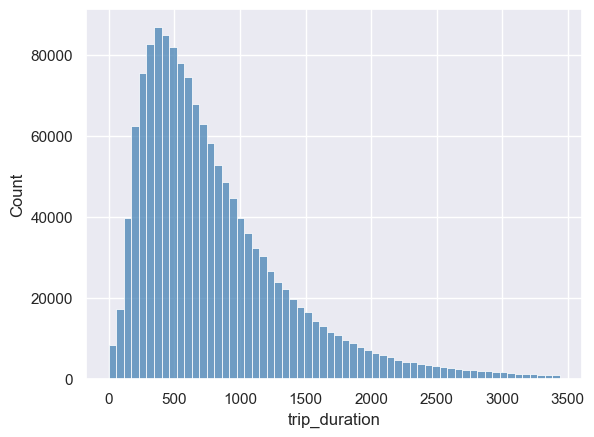

In [11]:
sns.histplot(train_data.loc[mask, "trip_duration"], bins=60, color="steelblue")
plt.show()

**Вопрос**: Что можно сказать о целевой переменной по гистограмме её значений?

*В силу размазанности значений, фигура получается очень крупного масштаба, вследствии этого диаграмма значений неинформативна.
Куда логичнее, по моему мнению, использовать логарифм этого столбца, чтобы получить более релевантную картину*


В соревновании в качестве метрики качества использовалось RMSLE:
$$\text{RMSLE}(X, y, a) = \sqrt{\frac{1}{\ell}\sum_{i=1}^{\ell} \big(\log{(y_i + 1)} - \log{(a(x_i) + 1)}\big)^2}$$

**Вопрос**: Как вы думаете, почему авторы соревнования выбрали именно RMSLE, а не MSE?

*Ответ на этот вопрос логично вытекает из моих предыдущих рассуждений. Из-за природы target-столбца MSE(или RMSE) учитывало бы погрешность
вне зависимости от величины значений, в то время как RMSLE смотрит на относительную погрешность, что в данной задаче куда перспективнее*

На семинаре мы рассматривали несколько моделей линейной регрессии в `sklearn`, но каждая из них оптимизировала среднеквадратичную ошибку (MSE), а не RMSLE. Давайте проделаем следующий трюк: будем предсказывать не целевую переменную, а ее *логарифм*. Обозначим $\hat{y}_i = \log{(y_i + 1)}$ — модифицированный таргет, а $\hat{a}(x_i)$ — предсказание модели, которая обучалась на $\hat{y}_i$, то есть логарифм таргета. Чтобы предсказать исходное значение, мы можем просто взять экспоненту от нашего предсказания: $a(x_i) = \exp(\hat{a}(x_i)) - 1$.

Итак, мы смогли свести задачу оптимизации RMSLE к задаче оптимизации MSE, которую мы умеем решать! Кроме того, у логарифмирования таргета есть еще одно полезное свойство. Чтобы его увидеть, добавьте к нашей выборке колонку `log_trip_duration` (воспользуйтесь `np.log1p`) и нарисуйте гистограмму модифицированного таргета по обучающей выборке. Удалите колонку со старым таргетом.

In [12]:
# ВАШ КОД
train_data['log_trip_duration'] = np.log1p(train_data['trip_duration'])
#test_data['log_trip_duration'] = np.log1p(test_data['trip_duration'])
train_data = train_data.drop(columns= 'trip_duration')

In [13]:
train_data.head()

,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,log_trip_duration
0,id2875421,2,2016-03-14 17:24:55,1,-73.982155,40.767937,-73.964630,40.765602,N,6.122493
1,id2377394,1,2016-06-12 00:43:35,1,-73.980415,40.738564,-73.999481,40.731152,N,6.498282
2,id3858529,2,2016-01-19 11:35:24,1,-73.979027,40.763939,-74.005333,40.710087,N,7.661527
3,id3504673,2,2016-04-06 19:32:31,1,-74.010040,40.719971,-74.012268,40.706718,N,6.063785
4,id2181028,2,2016-03-26 13:30:55,1,-73.973053,40.793209,-73.972923,40.782520,N,6.077642


In [14]:
mask = train_data['log_trip_duration']<train_data['log_trip_duration'].quantile(0.99)

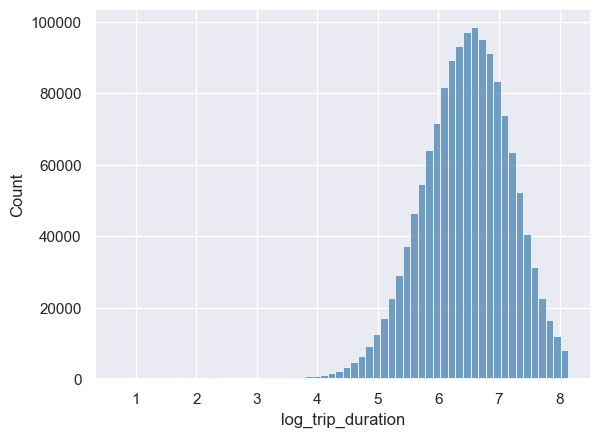

In [15]:
sns.histplot(train_data.loc[mask, "log_trip_duration"], bins=60, color="steelblue")
plt.show()

`log1p` сжимает длинный правый хвост


Чтобы иметь некоторую точку отсчета, давайте посчитаем значение метрики при наилучшем константном предсказании:

In [16]:
# ВАШ КОД
from sklearn.metrics import mean_squared_error
print(mean_squared_error([train_data['log_trip_duration'].mean()]*len(train_data['log_trip_duration']), train_data['log_trip_duration']))

0.6332327625405553


## Часть 1. Изучаем `pickup_datetime`

**Задание 2**. Для начала давайте посмотрим, сколько всего было поездок в каждый из дней. Постройте график зависимости количества поездок от дня в году (например, можно воспользоваться `sns.countplot`):

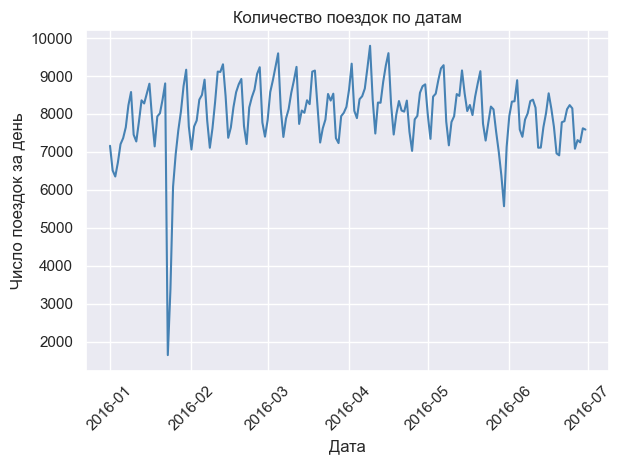

In [17]:
train_data["date"] = train_data["pickup_datetime"].dt.date
trips_by_date = train_data.groupby("date").size().reset_index(name="count").sort_values("date")
sns.lineplot(data=trips_by_date, x="date", y="count", linewidth=1.5, color="steelblue")
plt.title("Количество поездок по датам")
plt.xlabel("Дата")
plt.ylabel("Число поездок за день")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Вопрос**: Вы, вероятно, заметили, что на графике есть 2 периода с аномально маленькими количествами поездок. Вычислите, в какие даты происходили эти скачки вниз и найдите информацию о том, что происходило в эти дни в Нью-Йорке.

*23 и 24 января 2016 года в Нью-Йорке из-за снежной бури «Джонас» было запрещено автомобильное движение.*


*3 июля 2016 года в Центральном парке (в районе пересечения Пятой авеню и 68-й улицы) произошёл взрыв. 
8 июля 2016 года в Нью-Йорке прошли акции протеста против действий полиции*

Нарисуйте графики зависимости количества поездок от дня недели и от часов в сутках (воспользуйтесь `sns.relplot`):

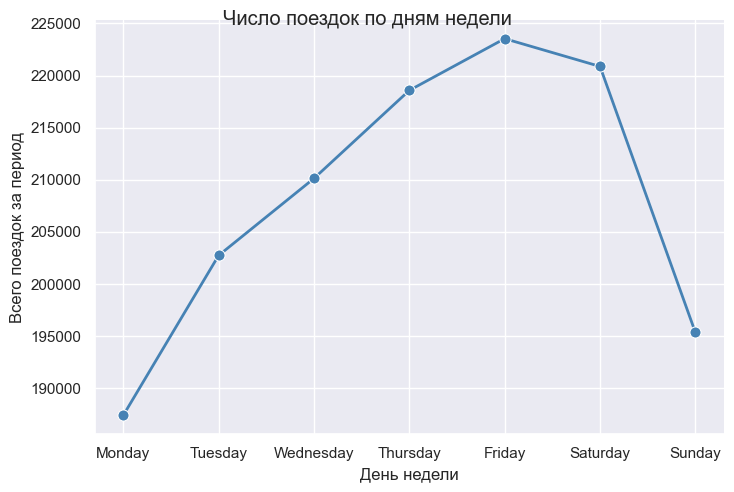

In [18]:
train_data["day_of_week"] = train_data["pickup_datetime"].dt.day_name()
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
trips_by_day = train_data.groupby("day_of_week").size().reindex(day_order).reset_index(name="count")
g = sns.relplot(data=trips_by_day, x="day_of_week", y="count", kind="line", marker="o", markersize=8, linewidth=2, color="steelblue", height=5, aspect=1.5)
g.set_axis_labels("День недели", "Всего поездок за период")
g.fig.suptitle("Число поездок по дням недели")
plt.show()

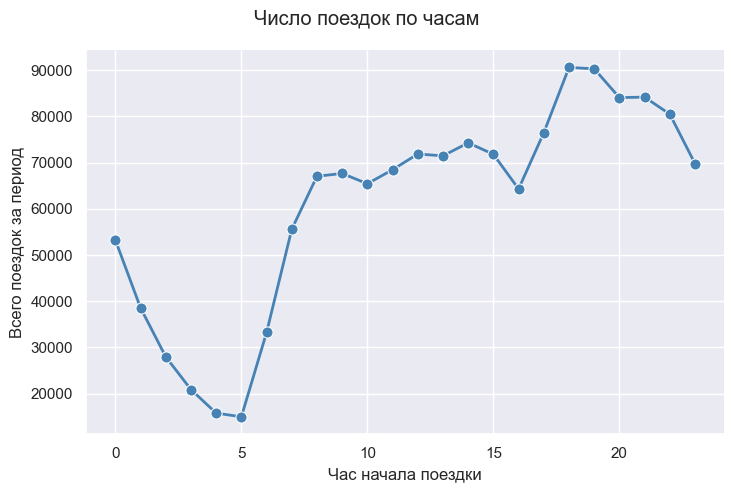

In [19]:
train_data["hour"] = train_data["pickup_datetime"].dt.hour
trips_by_hour = train_data.groupby("hour").size().reindex(range(24), fill_value=0).reset_index(name="count")
g = sns.relplot(data=trips_by_hour, x="hour", y="count", kind="line", marker="o", markersize=8, linewidth=2, color="steelblue", height=5, aspect=1.5)
g.set_axis_labels("Час начала поездки", "Всего поездок за период")
g.fig.suptitle("Число поездок по часам")
g.fig.subplots_adjust(top=0.90)
plt.show()

**Задание 3**. Нарисуйте на одном графике зависимости количества поездок от часа в сутках для разных месяцев (разные кривые, соответствующие разным месяцам, окрашивайте в разные цвета, воспользуйтесь `hue` в `sns.relplot`). Аналогично нарисуйте зависимости количества поездок от часа в сутках для разных дней недели.

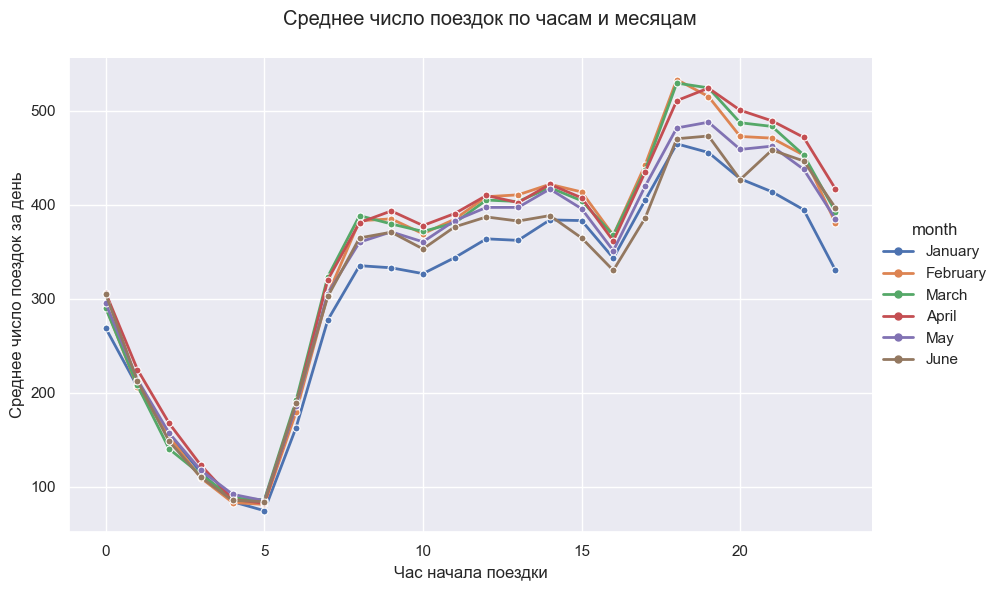

In [20]:

pickup_time = train_data["pickup_datetime"]
date_hour_counts = train_data.groupby([
    pickup_time.dt.normalize().rename("pickup_date"),
    pickup_time.dt.hour.rename("hour"),
]).size().rename("trips").reset_index()
calendar_days = pd.DataFrame({"pickup_date": pickup_time.dt.normalize().drop_duplicates().sort_values().to_numpy()})
daily_hourly = calendar_days.merge(pd.DataFrame({"hour": np.arange(24)}), how="cross")
daily_hourly = daily_hourly.merge(date_hour_counts, on=["pickup_date", "hour"], how="left")
daily_hourly["trips"] = daily_hourly["trips"].fillna(0)
daily_hourly["month"] = daily_hourly["pickup_date"].dt.month_name()
month_order = ["January", "February", "March", "April", "May", "June"]
trips_by_month_hour = daily_hourly.groupby(["month", "hour"], observed=False)["trips"].mean().reset_index(name="avg_trips_per_day")
trips_by_month_hour["month"] = pd.Categorical(trips_by_month_hour["month"], categories=month_order, ordered=True)
trips_by_month_hour = trips_by_month_hour.sort_values(["month", "hour"])
g = sns.relplot(data=trips_by_month_hour, x="hour", y="avg_trips_per_day", hue="month", hue_order=month_order, kind="line", marker="o", markersize=5, linewidth=2, height=6, aspect=1.5)
g.set_axis_labels("Час начала поездки", "Среднее число поездок за день")
g.fig.suptitle("Среднее число поездок по часам и месяцам")
g.fig.subplots_adjust(top=0.90)
plt.show()

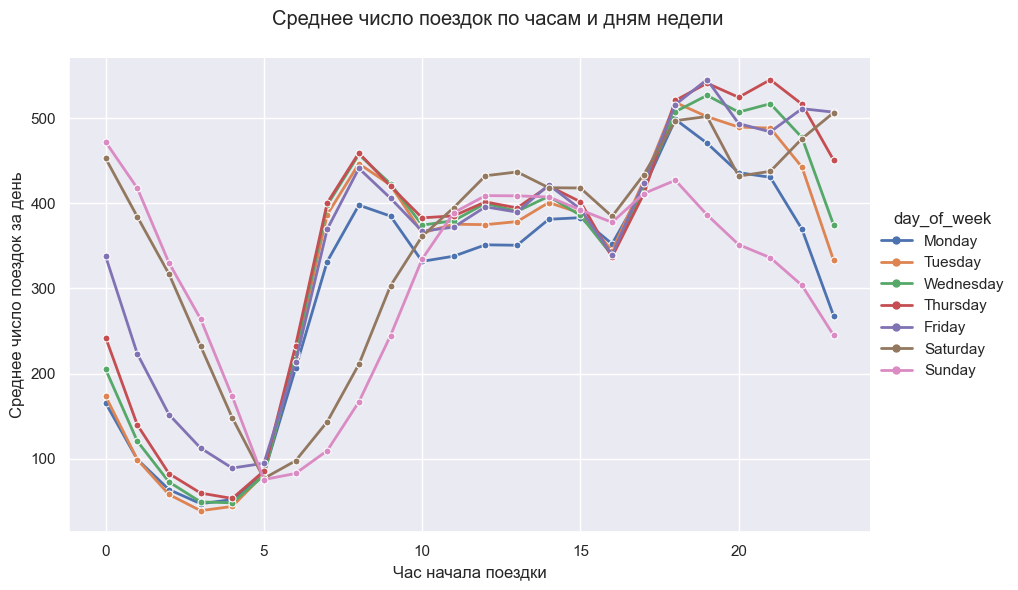

In [21]:

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily_hourly["day_of_week"] = daily_hourly["pickup_date"].dt.day_name()
trips_by_weekday_hour = daily_hourly.groupby(["day_of_week", "hour"], observed=False)["trips"].mean().reset_index(name="avg_trips_per_day")
trips_by_weekday_hour["day_of_week"] = pd.Categorical(trips_by_weekday_hour["day_of_week"], categories=day_order, ordered=True)
trips_by_weekday_hour = trips_by_weekday_hour.sort_values(["day_of_week", "hour"])
g = sns.relplot(data=trips_by_weekday_hour, x="hour", y="avg_trips_per_day", hue="day_of_week", hue_order=day_order, kind="line", marker="o", markersize=5, linewidth=2, height=6, aspect=1.5)
g.set_axis_labels("Час начала поездки", "Среднее число поездок за день")
g.fig.suptitle("Среднее число поездок по часам и дням недели")
g.fig.subplots_adjust(top=0.90)
plt.show()


**Вопрос**: Какие выводы можно сделать, основываясь на графиках выше? Выделяются ли какие-нибудь дни недели? Месяца? Время суток? С чем это связано?

**Задание 4**. Разбейте выборку (`train.csv`) на обучающую и тестовую в отношении 7:3. По обучающей выборке нарисуйте график зависимости среднего логарифма времени поездки от дня недели. Затем сделайте то же самое, но для часа в сутках и дня в году.

In [22]:
from sklearn.model_selection import train_test_split

train_idx, val_idx = train_test_split(
    train_data.index.to_numpy(), test_size=0.3, random_state=42
)
train = train_data.loc[train_idx].copy()
val = train_data.loc[val_idx].copy()
print(f"Строк train: {len(train):,}; строк val: {len(val):,}")

Строк train: 1,021,050; строк val: 437,594


**Про память:** полный train делится один раз. Новые признаки присоединяются к `X_train`/`X_val` по сохранённым индексам через `.loc`; поздний split `X_train` используется только для подбора alpha внутри train.

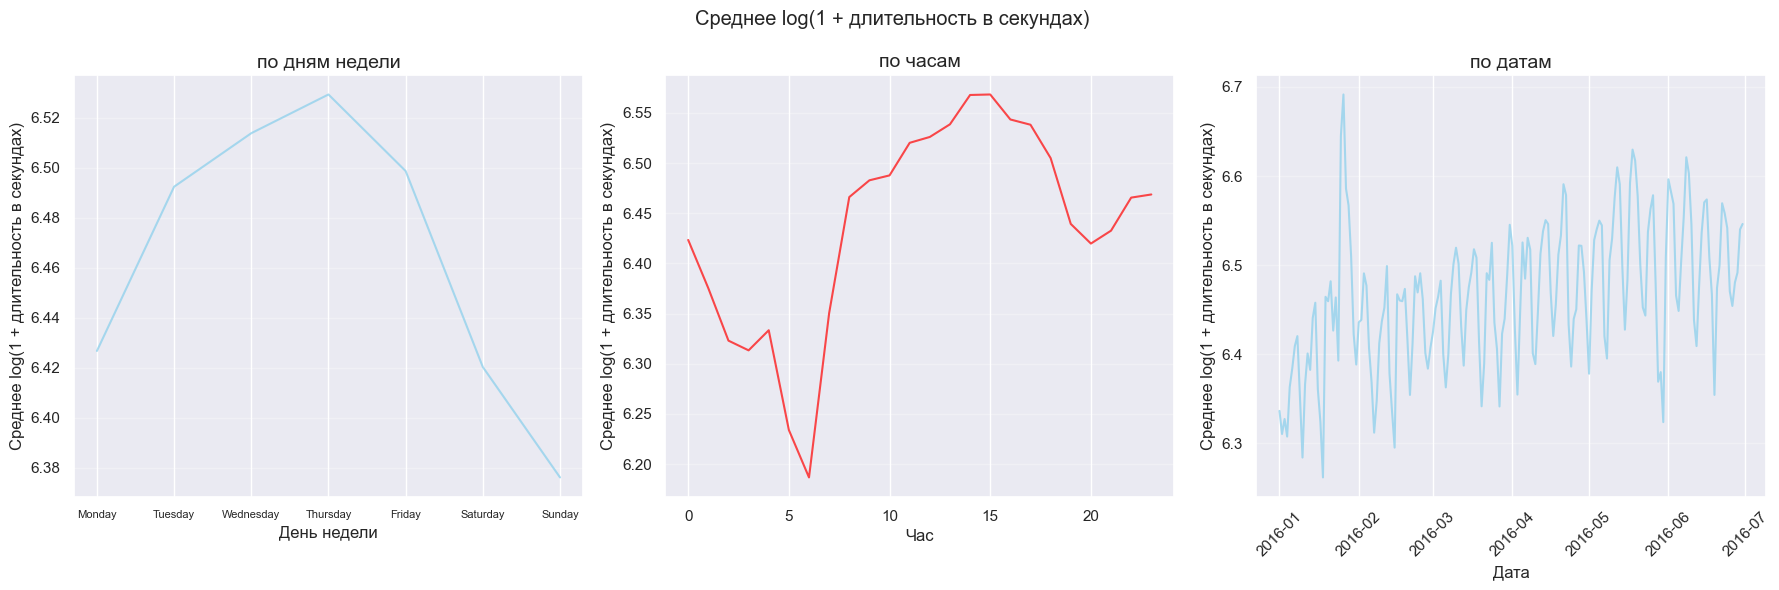

In [23]:
mean_by_day = train.groupby('day_of_week')['log_trip_duration'].mean().reset_index(name = 'mean_trips')
mean_by_day['day_of_week'] = pd.Categorical(mean_by_day['day_of_week'],
                                            categories = day_order,
                                            ordered=True)
mean_by_day = mean_by_day.sort_values('day_of_week')
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
sns.lineplot(data=mean_by_day, x='day_of_week', y='mean_trips',
            color='skyblue', alpha=0.7, ax = axes[0])
axes[0].set_xlabel('День недели', fontsize=12)
axes[0].tick_params(axis='x', labelsize=8)
axes[0].set_ylabel('Среднее log(1 + длительность в секундах)', fontsize=12)
axes[0].set_title('по дням недели', fontsize=14)
axes[0].grid(True, alpha=0.3, axis='y')
mean_hour = train.groupby('hour')['log_trip_duration'].mean().reset_index(name = 'mean_log')
sns.lineplot(data=mean_hour, x='hour', y='mean_log',
            color='red', alpha=0.7, ax = axes[1])
axes[1].set_xlabel('Час', fontsize=12)
axes[1].set_ylabel('Среднее log(1 + длительность в секундах)', fontsize=12)
axes[1].set_title('по часам', fontsize=14)
axes[1].grid(True, alpha=0.3, axis='y')
train['date'] = train['pickup_datetime'].dt.date
mean_by_date = train.groupby('date')['log_trip_duration'].mean().reset_index(name = 'mean_trips')
sns.lineplot(data=mean_by_date, x='date', y='mean_trips',
            color='skyblue', alpha=0.7, ax = axes[2])
axes[2].set_xlabel('Дата', fontsize=12)
axes[2].set_ylabel('Среднее log(1 + длительность в секундах)', fontsize=12)
axes[2].set_title('по датам', fontsize=14)
axes[2].grid(True, alpha=0.3, axis='y')
plt.suptitle('Среднее log(1 + длительность в секундах)')
axes[2].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

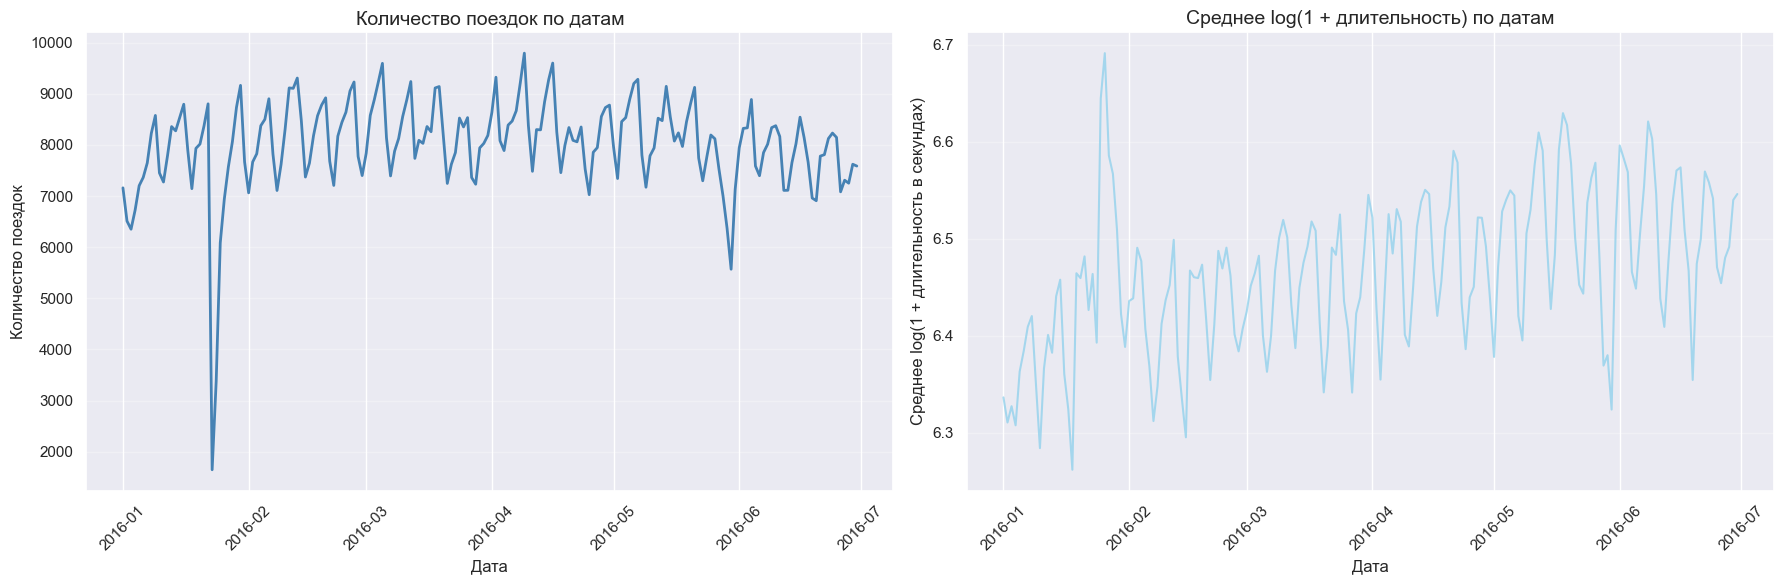

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.lineplot(
    data=trips_by_date,
    x='date',
    y='count',
    linewidth=2,
    color='steelblue',
    ax=axes[0]
)

axes[0].set_xlabel('Дата', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_ylabel('Количество поездок', fontsize=12)
axes[0].set_title('Количество поездок по датам', fontsize=14)
axes[0].grid(True, alpha=0.3, axis='y')

train['date'] = train['pickup_datetime'].dt.date

mean_by_date = (
    train.groupby('date')['log_trip_duration']
         .mean()
         .reset_index(name='mean_trips')
)

sns.lineplot(
    data=mean_by_date,
    x='date',
    y='mean_trips',
    color='skyblue',
    alpha=0.7,
    ax=axes[1]
)

axes[1].set_xlabel('Дата', fontsize=12)
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylabel('Среднее log(1 + длительность в секундах)', fontsize=12)
axes[1].set_title('Среднее log(1 + длительность) по датам', fontsize=14)
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


**Вопрос**: Похожи ли графики зависимости таргета от дня недели и от часа в сутках на аналогичные графики для количества поездок? Почему? Что происходит со средним таргетом в те два аномальных периода, что мы видели выше? Почему так происходит? Наблюдаете ли вы какой-нибудь тренд на графике зависимости `log_trip_duration` от номера дня в году?

*Не сказал бы что графики зависимости таргета от дня недели и часа в сутках похожи на аналогичные графики для количества поездок.
Что впринципе и логично, так как(просто исходя из интуиции и жизненого опыта) продолжительность поездки, вообще говоря, не связана с количеством этих поездок
как во временной промежуток, так и с днём недели.*
    
*Один из аномальных периодов сильно бросается в глаза(день бури), там продолжительность поездки аномальна 
высока(Это в какой-то степени логично, люди если и передвигались, то только если на относительно большие расстояния, в силу экономии средств и сильной надобности).
Во второй же аномальный период продолжительность поездки наоборот довольно низкая(это наверное связано с перекрытием улиц по которым осуществляется движение
такси).*

*Средняя продолжительность поездки растёт по мере течения времени от зимы к лету, что впринципе логично.*


Добавьте следующие признаки на основе `pickup_datetime`:
1. День недели
2. Месяц
3. Час
4. Является ли период аномальным (два бинарных признака, соответствующие двум аномальным периодам)
5. Номер дня в году

In [25]:
trips_by_date['anomaly'] = trips_by_date['count'] < 7000

trips_by_date['group'] = (
    trips_by_date['anomaly'] != trips_by_date['anomaly'].shift()
).cumsum()

anomaly_periods = (
    trips_by_date[trips_by_date['anomaly']]
    .groupby('group')['date']
    .agg(['min', 'max'])
    .reset_index(drop=True)
)

print(anomaly_periods)

          min         max
0  2016-01-02  2016-01-04
1  2016-01-23  2016-01-26
2  2016-05-29  2016-05-30
3  2016-06-19  2016-06-20


In [26]:
#train = train.drop(columns = ['anomaly', 'date'])

In [27]:
#train = train.drop(columns = 'num_day')

In [28]:
# ВАШ КОД
#train['date'] = train['pickup_datetime'].dt.date
train['month'] = train['pickup_datetime'].dt.month
train['anomaly 1'] = (
    (anomaly_periods['min'][1] <= train['date']) &
    (train['date'] <= anomaly_periods['max'][1])
)
train['anomaly 2'] = (
    (anomaly_periods['min'][3] <= train['date']) &
    (train['date'] <= anomaly_periods['max'][3])
)
#train.head()

In [29]:
train['day_of_year'] = train['pickup_datetime'].dt.dayofyear

In [30]:
val['day_of_year'] = val['pickup_datetime'].dt.dayofyear
val['date'] = val['pickup_datetime'].dt.date

In [31]:
train.head()

,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,log_trip_duration,date,day_of_week,hour,month,anomaly 1,anomaly 2,day_of_year
1011257,id2209155,2,2016-05-03 09:03:08,2,-73.979813,40.752529,-73.982681,40.763680,N,6.739337,2016-05-03,Tuesday,9,5,False,False,124
178550,id0586605,1,2016-01-01 16:40:51,1,-73.977623,40.746296,-73.968414,40.788933,N,6.909753,2016-01-01,Friday,16,1,False,False,1
551460,id0467144,1,2016-04-24 13:57:03,1,-73.950699,40.779404,-73.863129,40.768608,N,6.955593,2016-04-24,Sunday,13,4,False,False,115
1434271,id0989010,2,2016-01-10 17:03:47,1,-73.984558,40.721802,-73.976753,40.752213,N,6.665684,2016-01-10,Sunday,17,1,False,False,10
1173610,id0580742,1,2016-02-25 17:37:36,1,-73.967720,40.768742,-73.977173,40.789875,N,6.597146,2016-02-25,Thursday,17,2,False,False,56


In [32]:
val['month'] = val['pickup_datetime'].dt.month
val['anomaly 1'] = (
    (anomaly_periods['min'][1] <= val['date']) &
    (val['date'] <= anomaly_periods['max'][1])
)
val['anomaly 2'] = (
    (anomaly_periods['min'][3] <= val['date']) &
    (val['date'] <= anomaly_periods['max'][3])
)

In [33]:
train = train.drop(columns = 'date')
val = val.drop(columns = 'date')


Итак, мы уже создали некоторое количество признаков.

**Вопрос**: Какие из признаков стоит рассматривать как категориальные, а какие - как численные? Почему?

*День недели, месяца и рассмотрим как категориальные, так как у них нет числовой природы, на них не задан порядок и они "равноправны"
как отдельные признаки. Кроме 2 бинарных признаков, остался только день в году, он очевидно - числовой*

**Задание 5**. Обучите `Ridge`-регрессию с параметрами по умолчанию, закодировав все категориальные признаки с помощью `OneHotEncoder`. Численные признаки отмасштабируйте с помощью `StandardScaler`. Используйте только признаки, которые мы выделили в этой части задания.

In [34]:
# ВАШ КОД
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
day_of_week = {"Monday": 1, "Tuesday" : 2, "Wednesday" : 3, "Thursday" : 4, "Friday" : 5, "Saturday" : 6, "Sunday" : 7}
train['day_of_week'] = [day_of_week[i] for i in train['day_of_week']]
val['day_of_week'] = [day_of_week[i] for i in val['day_of_week']]
first_fetures = ['day_of_week', 'hour', 'month', 'anomaly 1', 'anomaly 2', 'day_of_year']
X_train = pd.DataFrame(data = train, columns = first_fetures)
y_train = train['log_trip_duration']
X_val = pd.DataFrame(data = val, columns = first_fetures)
y_val= val['log_trip_duration']

In [35]:
X_train.head()

,day_of_week,hour,month,anomaly 1,anomaly 2,day_of_year
1011257,2,9,5,False,False,124
178550,5,16,1,False,False,1
551460,7,13,4,False,False,115
1434271,7,17,1,False,False,10
1173610,4,17,2,False,False,56


In [36]:
ridge = Ridge()
ridge.fit(X_train, y_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [37]:
print(f'MSE on train : {mean_squared_error(ridge.predict(X_train), y_train)}')
print(f'MSE on validation : {mean_squared_error(ridge.predict(X_val), y_val)}')

MSE on train : 0.6304015587007181
MSE on validation : 0.628842864214573


## Часть 2. Изучаем координаты (3 балла)
Мы уже очень хорошо изучили данные о времени начала поездки, давайте теперь посмотрим на информацию о координатах начала и конца поездки. Мы подготовили для вас функцию, которая на карте рисует точки начала или конца поездки. Примеры ее вызова вы найдете ниже. Обратите внимание, что в эту функцию мы передаем лишь небольшой кусочек данных, посколько иначе функция будет работать очень долго

In [38]:
def show_circles_on_map(data, latitude_column, longitude_column, color):
    """
    The function draws map with circles on it.
    The center of the map is the mean of coordinates passed in data.
    
    data: DataFrame that contains columns latitude_column and longitude_column
    latitude_column: string, the name of column for latitude coordinates
    longitude_column: string, the name of column for longitude coordinates
    color: string, the color of circles to be drawn
    """

    location = (data[latitude_column].mean(), data[longitude_column].mean())
    m = folium.Map(location=location)

    for _, row in data.iterrows():
        folium.Circle(
            radius=100,
            location=(row[latitude_column], row[longitude_column]),
            color=color,
            fill_color=color,
            fill=True
        ).add_to(m)

    return m
    

**Вопрос**: Какие две точки выделяются на карте?


*Рядом с районами Clifton и Albertson*

**Задание 6**. Как мы все прекрасно помним, $t = s / v_{\text{ср}}$, поэтому очевидно, что самым сильным признаком будет расстояние, которое необходимо проехать. Мы не можем посчитать точное расстояние, которое необходимо преодолеть такси, но мы можем его оценить, посчитав кратчайшее расстояние между точками начала и конца поездки. Чтобы корректно посчитать расстояние между двумя точками на Земле, можно использовать функцию `sklearn.metrics.pairwise.haversine_distances`. Посчитайте кратчайшее расстояние для объектов и запишите его в колонку `haversine`:

In [39]:
train_data.head()

,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,log_trip_duration,date,day_of_week,hour
0,id2875421,2,2016-03-14 17:24:55,1,-73.982155,40.767937,-73.964630,40.765602,N,6.122493,2016-03-14,Monday,17
1,id2377394,1,2016-06-12 00:43:35,1,-73.980415,40.738564,-73.999481,40.731152,N,6.498282,2016-06-12,Sunday,0
2,id3858529,2,2016-01-19 11:35:24,1,-73.979027,40.763939,-74.005333,40.710087,N,7.661527,2016-01-19,Tuesday,11
3,id3504673,2,2016-04-06 19:32:31,1,-74.010040,40.719971,-74.012268,40.706718,N,6.063785,2016-04-06,Wednesday,19
4,id2181028,2,2016-03-26 13:30:55,1,-73.973053,40.793209,-73.972923,40.782520,N,6.077642,2016-03-26,Saturday,13


In [40]:
# ВАШ КОД
from sklearn.metrics.pairwise import haversine_distances
from tqdm.notebook import tqdm
def fast_haversine(train_data):

    lat1 = np.radians(train_data['pickup_latitude'])
    lon1 = np.radians(train_data['pickup_longitude'])
    
    lat2 = np.radians(train_data['dropoff_latitude'])
    lon2 = np.radians(train_data['dropoff_longitude'])
    
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    
    a = (
        np.sin(dlat / 2)**2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    )
    
    distance = 2 * np.arcsin(np.sqrt(a))
    
    train_data['haversine'] = distance * 6371
def pairwise_haversine(train_data):
    dist = []
    
    for i in tqdm(range(len(train_data))):
        points = np.radians([
            [
                train_data.iloc[i]['pickup_latitude'],
                train_data.iloc[i]['pickup_longitude']
            ],
            [
                train_data.iloc[i]['dropoff_latitude'],
                train_data.iloc[i]['dropoff_longitude']
            ]
        ])
    
        d = haversine_distances(points)[0, 1]
        dist.append(d * 6371)
    
    train_data['haversine'] = dist

In [41]:
fast_haversine(train_data)
#pairwise_haversine(train_data)

In [42]:
train_data.head(3)

,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,log_trip_duration,date,day_of_week,hour,haversine
0,id2875421,2,2016-03-14 17:24:55,1,-73.982155,40.767937,-73.964630,40.765602,N,6.122493,2016-03-14,Monday,17,1.498521
1,id2377394,1,2016-06-12 00:43:35,1,-73.980415,40.738564,-73.999481,40.731152,N,6.498282,2016-06-12,Sunday,0,1.805507
2,id3858529,2,2016-01-19 11:35:24,1,-73.979027,40.763939,-74.005333,40.710087,N,7.661527,2016-01-19,Tuesday,11,6.385098


Так как мы предсказываем логарифм времени поездки и хотим, чтобы наши признаки были линейно зависимы с этой целевой переменной, нам нужно логарифмировать расстояние: $\log t = \log s - \log{v_{\text{ср}}}$. Запишите логарифм `haversine` в отдельную колонку:

In [43]:
# ВАШ КОД
train_data['log_haversine'] = np.log1p(train_data['haversine'])
train_data.head()

,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,log_trip_duration,date,day_of_week,hour,haversine,log_haversine
0,id2875421,2,2016-03-14 17:24:55,1,-73.982155,40.767937,-73.964630,40.765602,N,6.122493,2016-03-14,Monday,17,1.498521,0.915699
1,id2377394,1,2016-06-12 00:43:35,1,-73.980415,40.738564,-73.999481,40.731152,N,6.498282,2016-06-12,Sunday,0,1.805507,1.031584
2,id3858529,2,2016-01-19 11:35:24,1,-73.979027,40.763939,-74.005333,40.710087,N,7.661527,2016-01-19,Tuesday,11,6.385098,1.999464
3,id3504673,2,2016-04-06 19:32:31,1,-74.010040,40.719971,-74.012268,40.706718,N,6.063785,2016-04-06,Wednesday,19,1.485498,0.910473
4,id2181028,2,2016-03-26 13:30:55,1,-73.973053,40.793209,-73.972923,40.782520,N,6.077642,2016-03-26,Saturday,13,1.188588,0.783257


Убедимся, что логарифм расстояния лучше коррелирует с нашим таргетом, чем просто расстояние:

In [44]:
# ВАШ КОД
corr1 = train_data['haversine'].corr(train_data['log_trip_duration'])
corr2 = train_data['log_haversine'].corr(train_data['log_trip_duration'])
print(f'Корреляция между таргетом и расстоянием: {corr1}')
print(f'Корреляция между таргетом и логарифмом расстояния: {corr2}')

Корреляция между таргетом и расстоянием: 0.5735948311180159
Корреляция между таргетом и логарифмом расстояния: 0.7498822373942501


**Задание 7**. Давайте изучим среднюю скорость движения такси. Посчитайте среднюю скорость для каждого объекта обучающей выборки, разделив `haversine` на `trip_duration`, и нарисуйте гистограмму ее распределения

In [45]:
mean_speed = train_data['haversine']*3600/trip_duration

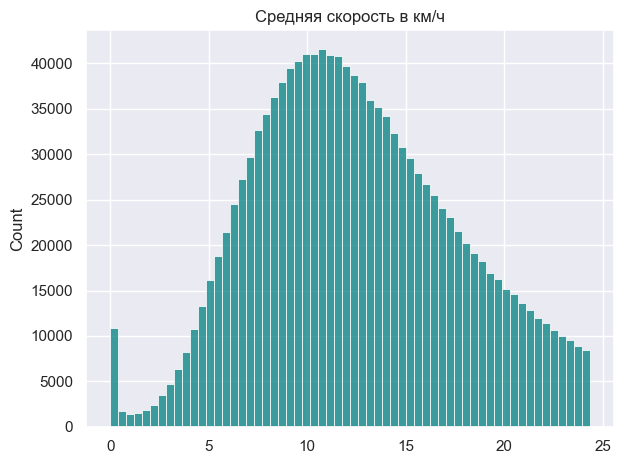

In [46]:
speed_for_plot = mean_speed[mean_speed < mean_speed.quantile(0.90)]
sns.histplot(speed_for_plot, bins=60, color="teal")
plt.title("Средняя скорость в км/ч")
plt.tight_layout()
plt.show()

Как можно видеть по гистограмме, для некоторых объектов у нас получились очень больше значения скоростей. Нарисуйте гистограмму по объектам, для которых значение скорости получилось разумным (например, можно не включать рассмотрение объекты, где скорость больше некоторой квантили):

In [47]:
# КОД ВЫШЕ

Для каждой пары (день недели, час суток) посчитайте медиану скоростей. Нарисуйте с помощью `sns.heatmap` график, где по осям будут дни недели и часы, а в качестве значения функции - медиана скорости

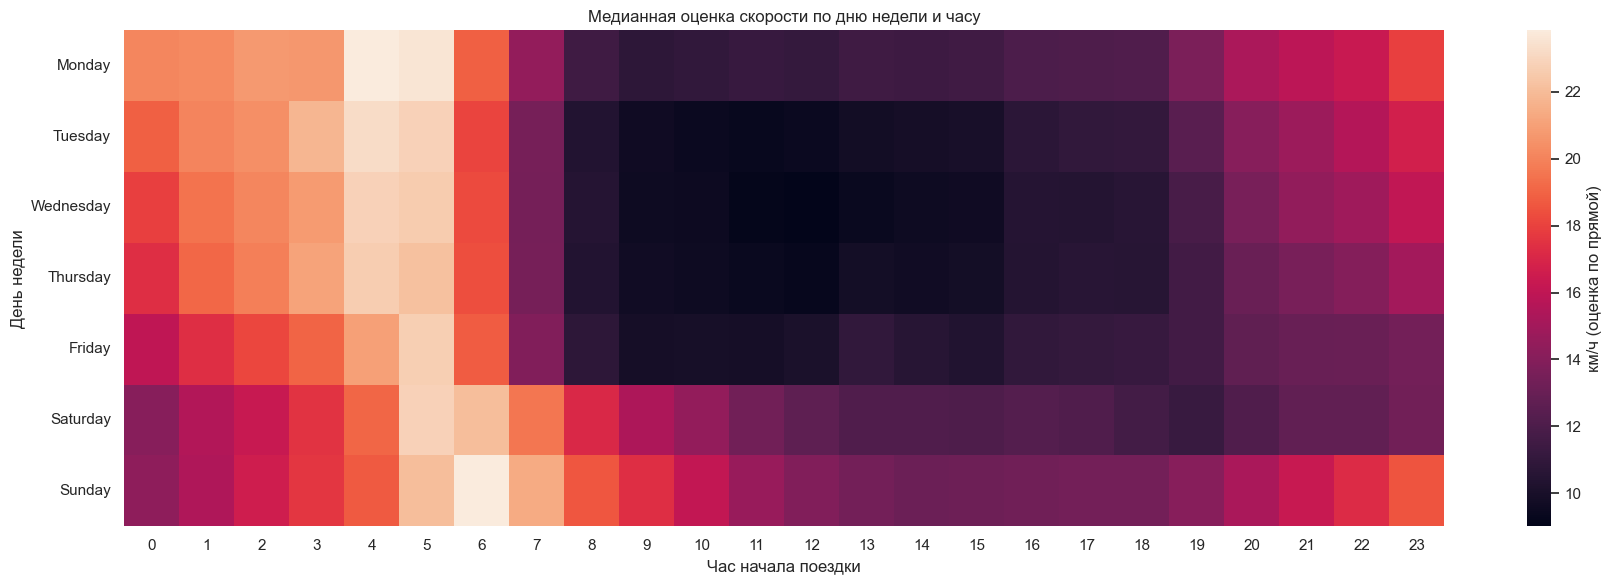

In [48]:
train_data["speed"] = mean_speed
heat_data = train_data.pivot_table(values="speed", index="day_of_week", columns="hour", aggfunc="median").reindex(day_order)
plt.figure(figsize=(18, 6))
sns.heatmap(heat_data, cbar_kws={"label": "км/ч (оценка по прямой)"})
plt.title("Медианная оценка скорости по дню недели и часу")
plt.ylabel("День недели")
plt.yticks(fontsize=11)
plt.xlabel("Час начала поездки")
plt.tight_layout()
plt.show()

Не забудьте удалить колонку со значением скорости из данных!

**Вопрос**: Почему значение скорости нельзя использовать во время обучения?

*target = np.dot(const, vehicle)*

**Вопрос**: Посмотрите внимательно на график и скажите, в какие моменты времени скорость минимальна; максимальна.

Создайте признаки "поездка совершается в период пробок" и "поездка совершается в период свободных дорог" (естественно, они не должен зависеть от скорости!):

In [49]:
# Интервалы выбраны по heatmap как часы устойчиво низкой скорости.
WEEKDAY_JAM_START, WEEKDAY_JAM_END = 7, 20
WEEKEND_JAM_START, WEEKEND_JAM_END = 10, 19
pickup_time = pd.to_datetime(train_data["pickup_datetime"])
weekday = pickup_time.dt.dayofweek
hour = pickup_time.dt.hour
weekday_rush = (weekday < 5) & hour.between(WEEKDAY_JAM_START, WEEKDAY_JAM_END)
weekend_rush = (weekday >= 5) & hour.between(WEEKEND_JAM_START, WEEKEND_JAM_END)
train_data["trip_in_trafficjam"] = (weekday_rush | weekend_rush).fillna(False).astype(bool)

In [50]:
train_data = train_data.drop(columns = 'speed')


**Задание 8**. Как уже было замечено выше, на карте выделяются две точки вдали от Манхэттена. Для каждой из них добавьте в выборку два признака: началась ли поездка в ней и закончилась ли она в ней.

In [51]:
# ВАШ КОД
#А вообще для чего это делать, и как это может быть признаком, если каждый объект характеризуется 2мя точками.
#Что значит вообще закончилась в этой точке?
train_data['haversine'].sort_values(ascending = False)

184925     1240.908677
974378      891.214103
910072      578.842818
1100676     574.875442
923793      562.235188
              ...     
402605        0.000000
111245        0.000000
818609        0.000000
17947         0.000000
301401        0.000000
Name: haversine, Length: 1458644, dtype: float64

Для каждого из созданных признаков нарисуйте "ящик с усами" (`sns.boxplot`) распределения логарифма времени поездки

In [52]:
train_data.head(3)

,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,log_trip_duration,date,day_of_week,hour,haversine,log_haversine,trip_in_trafficjam
0,id2875421,2,2016-03-14 17:24:55,1,-73.982155,40.767937,-73.964630,40.765602,N,6.122493,2016-03-14,Monday,17,1.498521,0.915699,True
1,id2377394,1,2016-06-12 00:43:35,1,-73.980415,40.738564,-73.999481,40.731152,N,6.498282,2016-06-12,Sunday,0,1.805507,1.031584,False
2,id3858529,2,2016-01-19 11:35:24,1,-73.979027,40.763939,-74.005333,40.710087,N,7.661527,2016-01-19,Tuesday,11,6.385098,1.999464,True


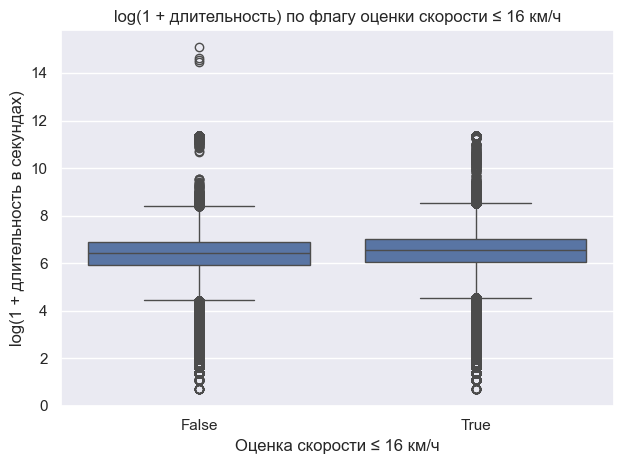

In [53]:
sns.boxplot(data=train_data, x="trip_in_trafficjam", y="log_trip_duration")
plt.title("log(1 + длительность) по флагу оценки скорости ≤ 16 км/ч")
plt.xlabel("Оценка скорости ≤ 16 км/ч")
plt.ylabel("log(1 + длительность в секундах)")
plt.tight_layout()
plt.show()

**Вопрос**: судя по графикам, как вы думаете, хорошими ли получились эти признаки?

<img src="https://www.dropbox.com/s/xson9nukz5hba7c/map.png?raw=1" align="right" width="20%" style="margin-left: 20px; margin-bottom: 20px">

**Задание 9**. Сейчас мы почти что не используем сами значения координат. На это есть несколько причин: по отдельности рассматривать широту и долготу не имеет особого смысла, стоит рассматривать их вместе. Во-вторых, понятно, что зависимость между нашим таргетом и координатами нелинейная. Чтобы как-то использовать координаты, можно прибегнуть к следующему трюку: обрамим область с наибольшим количеством поездок прямоугольником (как на рисунке). Разобьем этот прямоугольник на ячейки. Каждой точке сопоставим номер ее ячейки, а тем точкам, что не попали ни в одну из ячеек, сопоставим значение -1.

Напишите трансформер, который сначала разбивает показанную на рисунке область на ячейки, а затем создает два признака: номер ячейки, в которой началась поездка, и номер ячейки, в которой закончилась поездка. Количество строк и столбцов выберите самостоятельно.

Обратите внимание, что все вычисления должны быть векторизованными, трансформер не должен модифицировать передаваемую ему выборку inplace, а все необходимые статистики (если они вдруг нужны) нужно считать только по обучающей выборке в методе `fit`:

In [1]:
from matplotlib.colors import LogNorm
from sklearn.base import BaseEstimator, TransformerMixin
class MapGridTransformer(BaseEstimator, TransformerMixin):
    def __init__(
        self,
        n_rows=10,
        n_cols=10,
        focus_fraction=0.75,
        density_bins=80,
        trim_quantile=0.01,
        show_hist = False,
        pickup_lat_col="pickup_latitude",
        pickup_lon_col="pickup_longitude",
        dropoff_lat_col="dropoff_latitude",
        dropoff_lon_col="dropoff_longitude",
    ):
        self.n_rows = n_rows
        self.n_cols = n_cols
        self.focus_fraction = focus_fraction
        self.density_bins = density_bins
        self.trim_quantile = trim_quantile
        self.show_hist = show_hist
        self.pickup_lat_col = pickup_lat_col
        self.pickup_lon_col = pickup_lon_col
        self.dropoff_lat_col = dropoff_lat_col
        self.dropoff_lon_col = dropoff_lon_col

    def _get_coordinates(self, X):
        columns = [
            self.pickup_lat_col,
            self.pickup_lon_col,
            self.dropoff_lat_col,
            self.dropoff_lon_col,
        ]
        missing = [column for column in columns if column not in X.columns]
        if missing:
            raise ValueError(f"В данных отсутствуют колонки: {missing}")

        pickup_lat = pd.to_numeric(
            X[self.pickup_lat_col], errors="coerce"
        ).to_numpy(dtype=float)
        pickup_lon = pd.to_numeric(
            X[self.pickup_lon_col], errors="coerce"
        ).to_numpy(dtype=float)
        dropoff_lat = pd.to_numeric(
            X[self.dropoff_lat_col], errors="coerce"
        ).to_numpy(dtype=float)
        dropoff_lon = pd.to_numeric(
            X[self.dropoff_lon_col], errors="coerce"
        ).to_numpy(dtype=float)

        
        latitudes = np.concatenate([pickup_lat, dropoff_lat])
        longitudes = np.concatenate([pickup_lon, dropoff_lon])
        valid = np.isfinite(latitudes) & np.isfinite(longitudes)

        return latitudes[valid], longitudes[valid]

    def fit(self, X, y=None):
        if self.n_rows <= 0 or self.n_cols <= 0:
            raise ValueError("n_rows и n_cols должны быть положительными")
        if self.density_bins <= 0:
            raise ValueError("density_bins должен быть положительным")
        if not 0 < self.focus_fraction <= 1:
            raise ValueError("focus_fraction должен быть в интервале (0, 1]")
        if not 0 <= self.trim_quantile < 0.5:
            raise ValueError("trim_quantile должен быть в интервале [0, 0.5)")

        latitudes, longitudes = self._get_coordinates(X)
        if len(latitudes) == 0:
            raise ValueError("В обучающих данных нет корректных координат")

        
        q = self.trim_quantile
        lat_min, lat_max = np.quantile(latitudes, [q, 1 - q])
        lon_min, lon_max = np.quantile(longitudes, [q, 1 - q])

        if lat_min == lat_max or lon_min == lon_max:
            raise ValueError("Недостаточный разброс координат для построения сетки")

        # Гистограмма показывает, где сосредоточено больше всего точек.
        density, lat_edges, lon_edges = np.histogram2d(
            latitudes,
            longitudes,
            bins=(self.density_bins, self.density_bins),
            range=((lat_min, lat_max), (lon_min, lon_max)),
        )
        if self.show_hist:
            fig, ax = plt.subplots(figsize=(9, 8))
    
            im = ax.imshow(
                density.T,                 
                origin="lower",            # lat_min — внизу
                extent=[lon_min, lon_max, lat_min, lat_max],
                aspect="auto",
                cmap="viridis",
                norm=LogNorm(vmin=1),      # лог-шкала: иначе пик «забивает» всё
            )
            plt.colorbar(im, ax=ax, label="Число точек в бине")
            
            ax.set_xlabel("Долгота")
            ax.set_ylabel("Широта")
            ax.set_title("np.histogram2d(latitudes, longitudes, bins=(80, 80))")
            plt.tight_layout()
            plt.show()

       
        peak_row, peak_col = np.unravel_index(
            np.argmax(density), density.shape
        )
        target_count = self.focus_fraction * density.sum()

        for radius in range(self.density_bins + 1):
            row_start = max(0, peak_row - radius)
            row_end = min(self.density_bins, peak_row + radius + 1)
            col_start = max(0, peak_col - radius)
            col_end = min(self.density_bins, peak_col + radius + 1)

            points_in_area = density[row_start:row_end, col_start:col_end].sum()
            if points_in_area >= target_count:
                break

        self.lat_min_ = lat_edges[row_start]
        self.lat_max_ = lat_edges[row_end]
        self.lon_min_ = lon_edges[col_start]
        self.lon_max_ = lon_edges[col_end]
        self.is_fitted_ = True
        return self

    def transform(self, X):
        if not hasattr(self, "is_fitted_"):
            raise RuntimeError("Сначала вызовите fit на обучающих данных")

        pickup_lat = pd.to_numeric(
            X[self.pickup_lat_col], errors="coerce"
        ).to_numpy(dtype=float)
        pickup_lon = pd.to_numeric(
            X[self.pickup_lon_col], errors="coerce"
        ).to_numpy(dtype=float)
        dropoff_lat = pd.to_numeric(
            X[self.dropoff_lat_col], errors="coerce"
        ).to_numpy(dtype=float)
        dropoff_lon = pd.to_numeric(
            X[self.dropoff_lon_col], errors="coerce"
        ).to_numpy(dtype=float)

        def point_to_cell(latitude, longitude):
            valid = (
                np.isfinite(latitude)
                & np.isfinite(longitude)
                & (latitude >= self.lat_min_)
                & (latitude <= self.lat_max_)
                & (longitude >= self.lon_min_)
                & (longitude <= self.lon_max_)
            )

            safe_lat = np.where(np.isfinite(latitude), latitude, self.lat_min_)
            safe_lon = np.where(np.isfinite(longitude), longitude, self.lon_min_)

            row = np.floor(
                (safe_lat - self.lat_min_)
                / (self.lat_max_ - self.lat_min_)
                * self.n_rows
            ).astype(int)
            col = np.floor(
                (safe_lon - self.lon_min_)
                / (self.lon_max_ - self.lon_min_)
                * self.n_cols
            ).astype(int)

            
            row = np.clip(row, 0, self.n_rows - 1)
            col = np.clip(col, 0, self.n_cols - 1)

            cell_id = row * self.n_cols + col
            return np.where(valid, cell_id, -1)
    
        return pd.DataFrame(
            {
                "pickup_grid_cell": point_to_cell(pickup_lat, pickup_lon),
                "dropoff_grid_cell": point_to_cell(dropoff_lat, dropoff_lon),
            },
            index=X.index,
        )

    def show_map(self, data, n_points=1000, color="blue"):
        if not hasattr(self, "is_fitted_"):
            raise RuntimeError("Сначала вызовите fit на обучающих данных")

        # Собираем точки отправления и назначения, попавшие в плотную область.
        pickup = data[
            [self.pickup_lat_col, self.pickup_lon_col]
        ].copy()
        pickup.columns = ["latitude", "longitude"]

        dropoff = data[
            [self.dropoff_lat_col, self.dropoff_lon_col]
        ].copy()
        dropoff.columns = ["latitude", "longitude"]

        points = pd.concat([pickup, dropoff]).dropna()
        inside = (
            points["latitude"].between(self.lat_min_, self.lat_max_)
            & points["longitude"].between(self.lon_min_, self.lon_max_)
        )
        points = points.loc[inside]

        if points.empty:
            raise ValueError("В найденной области нет точек для отображения")

        if n_points is not None and len(points) > n_points:
            points = points.sample(n=n_points, random_state=42)

        # Используем функцию визуализации точек, уже определённую в ноутбуке.
        map_view = show_circles_on_map(
            points, "latitude", "longitude", color
        )
        map_view.fit_bounds([
            [self.lat_min_, self.lon_min_],
            [self.lat_max_, self.lon_max_],
        ])

        # Накладываем сетку только на область максимальной плотности.
        lat_edges = np.linspace(
            self.lat_min_, self.lat_max_, self.n_rows + 1
        )
        lon_edges = np.linspace(
            self.lon_min_, self.lon_max_, self.n_cols + 1
        )

        for row in range(self.n_rows):
            for col in range(self.n_cols):
                cell_id = row * self.n_cols + col
                folium.Rectangle(
                    bounds=[
                        [lat_edges[row], lon_edges[col]],
                        [lat_edges[row + 1], lon_edges[col + 1]],
                    ],
                    color="steelblue",
                    weight=1,
                    fill=False,
                    tooltip=f"Ячейка {cell_id}",
                ).add_to(map_view)

        return map_view

In [55]:
mapgrid = MapGridTransformer()
mapgrid.fit(train)
grid_features = mapgrid.transform(train_data)
for column in grid_features.columns:
    train_data[column] = grid_features[column]
assert train_data.columns.is_unique

**Задание 10**. Обучите `Ridge`-регрессию со стандартными параметрами на признаках, которые мы выделили к текущему моменту. Категориальные признаки закодируйте через one-hot-кодирование, числовые признаки отмасштабируйте.

In [56]:
train_data = train_data.drop(columns = 'haversine')

In [57]:
spatial_columns = ["log_haversine", "trip_in_trafficjam", "pickup_grid_cell", "dropoff_grid_cell"]
X_train[spatial_columns] = train_data.loc[X_train.index, spatial_columns].to_numpy()
X_val[spatial_columns] = train_data.loc[X_val.index, spatial_columns].to_numpy()

In [58]:
scaler = StandardScaler()
X_train[['log_haversine', 'pickup_grid_cell', 'dropoff_grid_cell']] = scaler.fit_transform(X_train[['log_haversine', 'pickup_grid_cell', 'dropoff_grid_cell']])
X_val[['log_haversine', 'pickup_grid_cell', 'dropoff_grid_cell']] = scaler.transform(X_val[['log_haversine', 'pickup_grid_cell', 'dropoff_grid_cell']])
X_train.head()

,day_of_week,hour,month,anomaly 1,anomaly 2,day_of_year,log_haversine,trip_in_trafficjam,pickup_grid_cell,dropoff_grid_cell
1011257,2,9,5,False,False,124,-0.698774,True,0.442415,1.096618
178550,5,16,1,False,False,1,0.802505,True,0.131843,-1.171250
551460,7,13,4,False,False,115,1.405247,True,1.808935,-1.171250
1434271,7,17,1,False,False,10,0.377202,True,-1.141505,0.522091
1173610,4,17,2,False,False,56,-0.012415,True,1.125675,-1.171250


In [59]:
ridge2 = Ridge()
ridge2.fit(X_train, y_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [60]:
print(f'MSE on train : {mean_squared_error(ridge2.predict(X_train), y_train)}')
print(f'MSE on validation : {mean_squared_error(ridge2.predict(X_val), y_val)}')

MSE on train : 0.2564527453679978
MSE on validation : 0.25599366721049865


## Часть 3. Изучаем оставшиеся признаки

**Задание 11**. У нас осталось еще 3 признака, которые мы не исследовали: `vendor_id`, `passenger_count` и `store_and_fwd_flag`.

**Вопрос**: Подумайте, почему каждый из этих признаков может быть потенциально полезным.

***store_and_fwd_flag:***

| Значение | Смысл                                                                                                               |
| -------- | ---------------------------------------------------------------------------------------------------------------------- |
| `N`      | запись была сразу отправлена на сервер                                                                                 |
| `Y`      | у такси не было соединения с сервером, поэтому запись временно сохранилась в памяти автомобиля и была отправлена позже |


Посчитайте, сколько есть уникальных значений у каждого из этих признаков:

In [61]:
# ВАШ КОД
ven = train_data['vendor_id'].nunique()
pc = train_data['passenger_count'].nunique()
sf = train_data['store_and_fwd_flag'].nunique()
print(f'vendor_id: {ven}')
print(f'passenger_count: {pc}')
print(f'store_and_fwd_flag: {sf}')

vendor_id: 2
passenger_count: 10
store_and_fwd_flag: 2


Постройте "ящики с усами" распределений логарифма времени поездки в зависимости от значений каждого из признаков

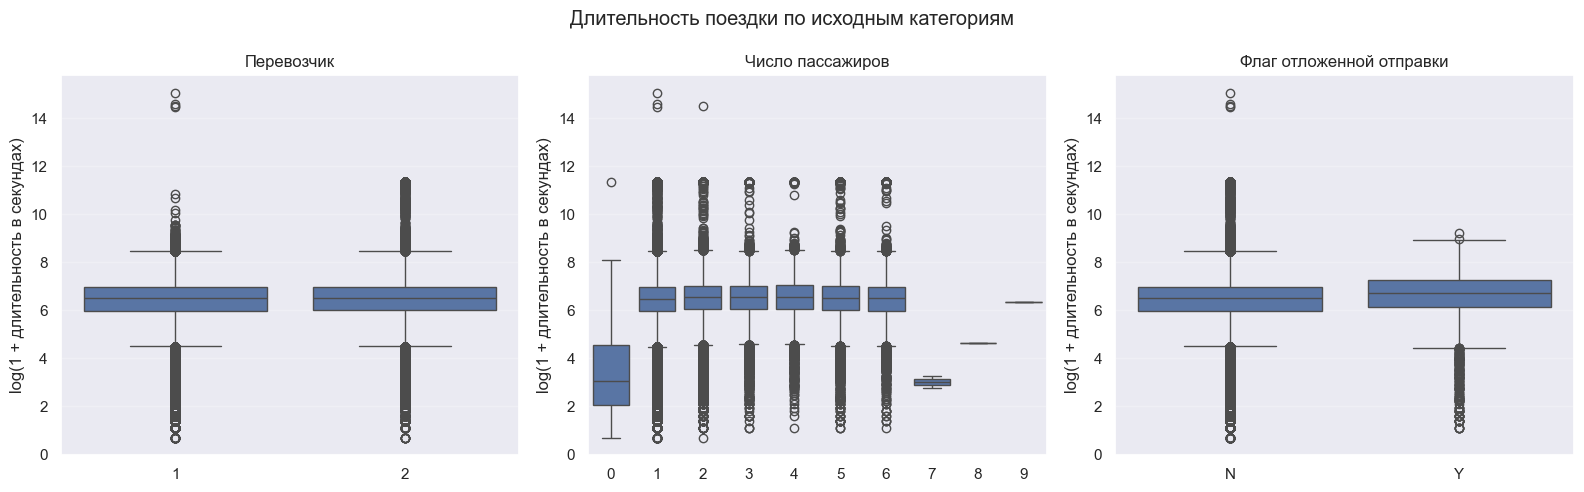

In [62]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sns.boxplot(data=train_data, x="vendor_id", y="log_trip_duration", ax=axes[0])
axes[0].set_title("Перевозчик")
sns.boxplot(data=train_data, x="passenger_count", y="log_trip_duration", ax=axes[1])
axes[1].set_title("Число пассажиров")
sns.boxplot(data=train_data, x="store_and_fwd_flag", y="log_trip_duration", ax=axes[2])
axes[2].set_title("Флаг отложенной отправки")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("log(1 + длительность в секундах)")
    ax.grid(True, axis="y", alpha=0.25)
fig.suptitle("Длительность поездки по исходным категориям")
fig.tight_layout()
plt.show()

Переведите признаки `vendor_id` и `store_and_fwd_flag` в значения $\{0;1\}$

In [63]:
train_data['vendor_id'] = train_data['vendor_id']-1

In [64]:
train_data['store_and_fwd_flag'] = [1 if i == 'N' else 0 for i in train_data['store_and_fwd_flag']]

In [65]:
# ВАШ КОД
train_data.head()

,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,log_trip_duration,date,day_of_week,hour,log_haversine,trip_in_trafficjam,pickup_grid_cell,dropoff_grid_cell
0,id2875421,1,2016-03-14 17:24:55,1,-73.982155,40.767937,-73.964630,40.765602,1,6.122493,2016-03-14,Monday,17,0.915699,True,74,77
1,id2377394,0,2016-06-12 00:43:35,1,-73.980415,40.738564,-73.999481,40.731152,1,6.498282,2016-06-12,Sunday,0,1.031584,False,35,22
2,id3858529,1,2016-01-19 11:35:24,1,-73.979027,40.763939,-74.005333,40.710087,1,7.661527,2016-01-19,Tuesday,11,1.999464,True,75,-1
3,id3504673,1,2016-04-06 19:32:31,1,-74.010040,40.719971,-74.012268,40.706718,1,6.063785,2016-04-06,Wednesday,19,0.910473,True,0,-1
4,id2181028,1,2016-03-26 13:30:55,1,-73.973053,40.793209,-73.972923,40.782520,1,6.077642,2016-03-26,Saturday,13,0.783257,True,-1,-1


**Вопрос**: Основываясь на графиках выше, как вы думаете, будут ли эти признаки сильными?

*Я думаю что не очень, так как сильно шумные*

**Задание 12**. Проверьте свои предположения, обучив модель в том числе и на этих трех признаках. Обучайте `Ridge`-регрессию со стандартными параметрами. Категориальные признаки закодируйте one-hot-кодированием, а численные отмасштабируйте.

In [66]:
category_columns = ["passenger_count", "vendor_id", "store_and_fwd_flag"]
X_train[category_columns] = train_data.loc[X_train.index, category_columns].to_numpy()
X_val[category_columns] = train_data.loc[X_val.index, category_columns].to_numpy()

In [67]:
scaler = StandardScaler()
X_train['passenger_count'] = scaler.fit_transform(X_train[['passenger_count']])
X_val['passenger_count'] = scaler.transform(X_val[['passenger_count']])
X_train.head()

,day_of_week,hour,month,anomaly 1,anomaly 2,day_of_year,log_haversine,trip_in_trafficjam,pickup_grid_cell,dropoff_grid_cell,passenger_count,vendor_id,store_and_fwd_flag
1011257,2,9,5,False,False,124,-0.698774,True,0.442415,1.096618,0.256446,1,1
178550,5,16,1,False,False,1,0.802505,True,0.131843,-1.171250,-0.505346,0,1
551460,7,13,4,False,False,115,1.405247,True,1.808935,-1.171250,-0.505346,0,1
1434271,7,17,1,False,False,10,0.377202,True,-1.141505,0.522091,-0.505346,1,1
1173610,4,17,2,False,False,56,-0.012415,True,1.125675,-1.171250,-0.505346,0,1


In [68]:
ridge3 = Ridge()
ridge3.fit(X_train, y_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [69]:
print(f'MSE on train : {mean_squared_error(ridge3.predict(X_train), y_train)}')
print(f'MSE on validation : {mean_squared_error(ridge3.predict(X_val), y_val)}')

MSE on train : 0.2562797568620044
MSE on validation : 0.255813799969971


Если признаки не дали какого-то ощутимого улучшения метрики, их можно выбросить из данных.

In [70]:
X_train = X_train.drop(columns = ['passenger_count', 'vendor_id', 'store_and_fwd_flag'])
X_val = X_val.drop(columns = ['passenger_count', 'vendor_id', 'store_and_fwd_flag'])

## Часть 4. Улучшаем модель (дополнительная часть)

**Задание 13**. В наших данных есть нетипичные объекты: с аномально маленьким времени поездки, с очень большим пройденным расстоянием или очень большими остатками регрессии. В этом задании предлагается исключить такие объекты из обучающей выборки. Для этого нарисуйте гистограммы распределения упомянутых выше величин, выберите объекты, которые можно назвать выбросами, и очистите обучающую выборку от них.

Отметим, что хотя эти объекты и выглядят как выбросы, в тестовой выборке тоже скорее всего будут объекты с такими же странными значениями целевой переменной и/или признаков. Поэтому, возможно, чистка обучающей выборки приведёт к ухудшению качества на тесте. Тем не менее, всё равно лучше удалять выбросы из обучения, чтобы модель получалась более разумной и интерпретируемой.

In [71]:
# ВАШ КОД
y_train_index = y_train[y_train<y_train.quantile(0.0001)].index
X_train = X_train.drop(index = y_train_index)
y_train = y_train.drop(index = y_train_index)

In [72]:
log_haversine = X_train['log_haversine']
log_hav_index = log_haversine[log_haversine>log_haversine.quantile(0.99999)].index
X_train = X_train.drop(index = log_hav_index)
y_train = y_train.drop(index = log_hav_index)


Сейчас у нас очень много категориальных признаков. В категориальных признаках могут содержаться редкие категории, обычно это плохо: модель сильно переобучается на таких примерах. Попробуйте объединить редкие категории в одну. Естественно, делать это нужно только для действительно редких категорий.

In [73]:
# ВАШ КОД
# У меня нет таких катeгориальных признаков, в которых есть действительно редкие категории

Обучите модель на очищенных данных и посчитайте качество на тестовой выборке.

In [74]:
ridge4 = Ridge()
ridge4.fit(X_train, y_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [75]:
print(f'MSE on train : {mean_squared_error(ridge4.predict(X_train), y_train)}')
print(f'MSE on validation : {mean_squared_error(ridge4.predict(X_val), y_val)}')

MSE on train : 0.25575914831756397
MSE on validation : 0.25599313018861514


In [76]:
errors = (y_train - ridge4.predict(X_train))**2
error_index = errors[errors>errors.quantile(0.99999)].index

In [77]:
X_train = X_train.drop(index = error_index)
y_train = y_train.drop(index = error_index)

In [78]:
ridge5 = Ridge()
ridge5.fit(X_train, y_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [79]:
print(f'MSE on train : {mean_squared_error(ridge5.predict(X_train), y_train)}')
print(f'MSE on validation : {mean_squared_error(ridge5.predict(X_val), y_val)}')

MSE on train : 0.2552774614665986
MSE on validation : 0.25599357816962554


**Задание 14**. После OneHot-кодирования количество признаков в нашем датасете сильно возрастает. Посчитайте колиество признаков до и после кодирования категориальных признаков.

In [80]:
# ВАШ КОД
print(f'До One Hot: {len(train.columns)}')
print(f'После One Hot: {len(X_train.columns)}')

До One Hot: 16
После One Hot: 10


Попробуйте обучить не `Ridge`-, а `Lasso`-регрессию. Какой метод лучше?

In [81]:
# ВАШ КОД
from sklearn.linear_model import Lasso
lasso1 = Lasso()
lasso1.fit(X_train, y_train)

,alpha,1.0
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [82]:
print(f'MSE on train : {mean_squared_error(lasso1.predict(X_train), y_train)}')
print(f'MSE on validation : {mean_squared_error(lasso1.predict(X_val), y_val)}')

MSE on train : 0.6313655474993447
MSE on validation : 0.6310106953150026


*Ridge получше будет*

Разбейте обучающую выборку на обучающую и валидационную в отношении 8:2. По валидационной выборке подберите оптимальные значения параметра регуляризации (по логарифмической сетке) для `Ridge` и `Lasso`, на тестовой выборке измерьте качество лучшей полученной модели.

In [83]:
# ВАШ КОД
X_train2, X_val2, y_train2, y_val2 = train_test_split(X_train, y_train, test_size = 0.2, random_state=43)

In [84]:
from sklearn.model_selection import GridSearchCV
alphas_ridge = np.logspace(-2, 4, 20)
ridge_searcher = GridSearchCV(Ridge(), [{'alpha':alphas_ridge}], scoring = 'neg_mean_squared_error', cv = 5)

In [85]:
ridge_searcher.fit(X_val2, y_val2)

best_alpha_ridge = ridge_searcher.best_params_["alpha"]
print("Best Ridge alpha = %.4f" % best_alpha_ridge)

Best Ridge alpha = 6.9519


In [86]:
alphas_lasso = np.logspace(-2, 1, 20)
lasso_searcher = GridSearchCV(Lasso(), [{'alpha':alphas_lasso}], scoring = 'neg_mean_squared_error', cv = 5)

In [87]:
lasso_searcher.fit(X_val2, y_val2)

best_alpha_lasso = lasso_searcher.best_params_["alpha"]
print("Best Lasso alpha = %.4f" % best_alpha_lasso)

Best Lasso alpha = 0.0100


In [88]:
ridge6 = Ridge(best_alpha_ridge)
ridge6.fit(X_train2, y_train2)

,alpha,np.float64(6.951927961775605)
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [89]:
print(f'MSE on train : {mean_squared_error(ridge6.predict(X_train2), y_train2)}')
print(f'MSE on validation : {mean_squared_error(ridge6.predict(X_val), y_val)}')

MSE on train : 0.2540451804619944
MSE on validation : 0.2559947549897122


In [90]:
lasso2 = Lasso(best_alpha_lasso)
lasso2.fit(X_train2, y_train2)

,alpha,np.float64(0.01)
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [91]:
print(f'MSE on train : {mean_squared_error(lasso2.predict(X_train2), y_train2)}')
print(f'MSE on validation : {mean_squared_error(lasso2.predict(X_val), y_val)}')

MSE on train : 0.2553866164386561
MSE on validation : 0.25733892812518566


*Lasso заметно прибавила в качестве!*

Для каждого перебранного `alpha` для Lasso посчитайте количество нулевых весов в модели и нарисуйте график зависимости его от `alpha`. Как сильно придётся потерять в качестве, если мы хотим с помощью Lasso избавиться хотя бы от половины признаков?

In [92]:
# ВАШ КОД
from tqdm.notebook import tqdm
def counts_zero(arr):
    d = {}
    for i in arr:
        if i in d:
            d[i]+=1
        else:
            d[i]=1
    return d[0]
cnt_zeros = []
for i in tqdm(alphas_lasso):
    lasso = Lasso(i)
    lasso.fit(X_train2, y_train2)
    cnt_zeros.append(counts_zero(lasso.coef_))

  0%|          | 0/20 [00:00<?, ?it/s]

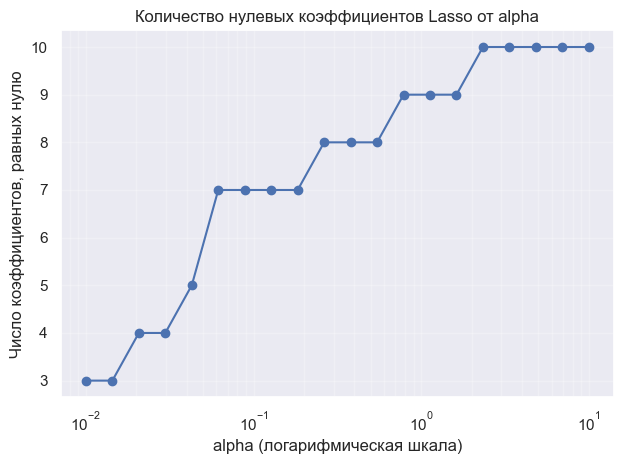

In [93]:
plt.plot(alphas_lasso, cnt_zeros, marker="o")
plt.xscale("log")
plt.title("Количество нулевых коэффициентов Lasso от alpha")
plt.xlabel("alpha (логарифмическая шкала)")
plt.ylabel("Число коэффициентов, равных нулю")
plt.grid(True, which="both", alpha=0.25)
plt.tight_layout()
plt.show()

<img src="https://www.dropbox.com/s/wp4jj0599np17lh/map_direction.png?raw=1" width="20%" align="right" style="margin-left: 20px">

**Задание 15**. Часто бывает полезным использовать взаимодействия признаков (feature interactions), то есть строить новые признаки на основе уже существующих. Выше мы разбили карту Манхэттена на ячейки и придумали признаки "из какой ячейки началась поездка" и "в какой ячейке закончилась поездка".

Давайте попробуем сделать следующее: посчитаем, сколько раз встречается каждая возможная пара этих признаков в нашем датасете и выберем 100 самых частых пар. Закодируем поездки с этими частыми парами как категориальный признак, остальным объектам припишем -1. Получается, что мы закодировали, откуда и куда должно было ехать такси.

Также можете придумать ещё какой-нибудь способ сделать признаки про маршрут. Если эти признаки будут давать хороший прирост в качестве, то за это могут быть даны **дополнительные плюсы при оценке работы**.

**Вопрос**: Почему такой признак потенциально полезный? Почему линейная модель не может самостоятельно "вытащить" эту информацию, ведь у нее в распоряжении есть признаки "из какой ячейки началась поездка" и "в какой ячейке закончилась поездка"?

*Избавление от выбросов. Линейная модель учитывает только аддитивный эффект от признака, она не строит между ними связи*

In [94]:

from collections import Counter

grid_pairs_train = zip(
    X_train["pickup_grid_cell"].to_numpy(),
    X_train["dropoff_grid_cell"].to_numpy(),
)
hash_map = Counter(grid_pairs_train)

In [96]:
top_100 = dict(sorted(hash_map.items(), key = lambda x: x[1], reverse = True)[:100])

In [97]:
# В validation используем те же 100 популярных train-маршрутов.
top_100_val = top_100

In [98]:
train_pairs = zip(
    X_train["pickup_grid_cell"].to_numpy(),
    X_train["dropoff_grid_cell"].to_numpy(),
)
X_train["often_pairs"] = [top_100.get(pair, -1) for pair in train_pairs]

In [99]:
val_pairs = zip(
    X_val["pickup_grid_cell"].to_numpy(),
    X_val["dropoff_grid_cell"].to_numpy(),
)
X_val["often_pairs"] = [top_100_val.get(pair, -1) for pair in val_pairs]

In [100]:
X_train.head()

,day_of_week,hour,month,anomaly 1,anomaly 2,day_of_year,log_haversine,trip_in_trafficjam,pickup_grid_cell,dropoff_grid_cell,often_pairs
1011257,2,9,5,False,False,124,-0.698774,True,0.442415,1.096618,-1
178550,5,16,1,False,False,1,0.802505,True,0.131843,-1.171250,2792
551460,7,13,4,False,False,115,1.405247,True,1.808935,-1.171250,5666
1434271,7,17,1,False,False,10,0.377202,True,-1.141505,0.522091,-1
1173610,4,17,2,False,False,56,-0.012415,True,1.125675,-1.171250,3505



Заново обучите модель (`Ridge`, если она дала более высокое качество в предыдущих экспериментах, и `Lasso` иначе) на новых даннных и посчитайте качество на тестовой выборке

In [101]:
# ВАШ КОД
ridge7 = Ridge()
ridge7.fit(X_train, y_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [102]:
print(f'MSE on train : {mean_squared_error(ridge7.predict(X_train), y_train)}')
print(f'MSE on validation : {mean_squared_error(ridge7.predict(X_val), y_val)}')

MSE on train : 0.2509889694073099
MSE on validation : 0.25178371379211095


**Задание 16**. Где, как не для нашей задачи, считать манхэттенское расстояние?

**Вопрос**: Найдите, что такое манхэттенское расстояние и почему оно так называется. Как оно нам может помочь?

#### Манхэттенское расстояние ($L_1$-норма)
Так же известная нам метрика. Задается формулой:
$$d(x,y)=\sum_{i=1}^n|x_i-y_i| $$
Почему его называют Манхэттенским? Вы просто взгляните на карту Нью-Йорка:

<img src="./Manhattan_map.jpg" style="max-width: 800px;">

**Формула для координат**

$$d = R \cdot \left( |\varphi_2 - \varphi_1| + \cos\left(\frac{\varphi_1 + \varphi_2}{2}\right) \cdot |\lambda_2 - \lambda_1| \right)$$

где:

- $\varphi_1, \varphi_2$ — широты точек *в радианах*,
- $\lambda_1, \lambda_2$ — долготы точек *в радианах*,
- $R = 6371$ км — радиус Земли,
- $\frac{\varphi_1 + \varphi_2}{2}$ — средняя широта (поправка на то, что
  один градус долготы «уже» одного градуса широты).

**Интуиция**

Расстояние складывается из «вертикальной» и «горизонтальной» составляющих,
как движение по кварталам (вверх-вниз и влево-вправо), а не по прямой.
Это длина кратчайшего пути по улицам, идущим строго по широте и долготе.

**Зачем нужен cos(средней широты)**

Например, в Нью-Йорке на широте около 40°:

- один градус широты ≈ 111 км — всегда,
- один градус долготы ≈ 111 · cos(40°) ≈ 85 км.

Без множителя `cos` мы бы переоценили «горизонтальную» часть пути,
причём тем сильнее, чем ближе к полюсу. Поэтому к градусам долготы
прибавляют коэффициент $\cos(\varphi_{ср})$.

Нам даже известны примеры, где применяется эта метрика. В регуляризации моделей:

Добавьте в данные признак "манхэттенское расстояние между пунктом отправления и пунктом назначения", а затем и логарифм этого признака. Посчитайте корреляцию между вашим новыми признаком и таргетом; между `log_haversine` и таргетом. В каком случае корреляция больше?

In [12]:

earth_radius_km = 6371.0
pickup_lat = np.radians(train_data["pickup_latitude"].to_numpy(dtype=float))
pickup_lon = np.radians(train_data["pickup_longitude"].to_numpy(dtype=float))
dropoff_lat = np.radians(train_data["dropoff_latitude"].to_numpy(dtype=float))
dropoff_lon = np.radians(train_data["dropoff_longitude"].to_numpy(dtype=float))
mean_lat = (pickup_lat + dropoff_lat) / 2

train_data["manhattan_distance"] = earth_radius_km * (
    np.abs(dropoff_lat - pickup_lat)
    + np.cos(mean_lat) * np.abs(dropoff_lon - pickup_lon)
)
train_data["log_manhattan_distance"] = np.log1p(
    train_data["manhattan_distance"]
)

manhattan_corr = train_data["log_manhattan_distance"].corr(
    train_data["log_trip_duration"]
)
haversine_corr = train_data["log_haversine"].corr(train_data["log_trip_duration"])
print(f"Корреляция Manhattan distance с log_trip_duration: {manhattan_corr:.4f}")
print(f"Корреляция log_haversine с log_trip_duration: {haversine_corr:.4f}")
print("Больше по модулю корреляция у:",
      "log_manhattan_distance" if abs(manhattan_corr) > abs(haversine_corr) else "log_haversine")

NameError: name 'train_data' is not defined

Заново обучите модель на новых даннных и посчитайте качество на тестовой выборке. Стало ли лучше? Объясните полученный результат.

In [104]:
# Добавляем новые признаки только в копии матриц, не меняя X_train и X_val.
manhattan_columns = ["manhattan_distance", "log_manhattan_distance"]
X_train[manhattan_columns] = train_data.loc[
    X_train.index, manhattan_columns
]
X_val[manhattan_columns] = train_data.loc[
    X_val.index, manhattan_columns
]

# Масштабируем новые числовые признаки, обучая scaler только на train.
manhattan_scaler = StandardScaler()
X_train[manhattan_columns] = manhattan_scaler.fit_transform(
    X_train[manhattan_columns]
)
X_val[manhattan_columns] = manhattan_scaler.transform(
    X_val[manhattan_columns]
)

In [105]:
ridge8 = Ridge()
ridge8.fit(X_train, y_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [106]:
print(f'MSE on train : {mean_squared_error(ridge8.predict(X_train), y_train)}')
print(f'MSE on validation : {mean_squared_error(ridge8.predict(X_val), y_val)}')

MSE on train : 0.2390219657967126
MSE on validation : 0.2439256591154474


In [107]:
from sklearn.metrics import root_mean_squared_log_error
print(f'RMSLE on train : {root_mean_squared_log_error(np.exp(ridge8.predict(X_train))-1, np.exp(y_train)-1)}')
print(f'RMSLE on validation : {root_mean_squared_log_error(np.exp(ridge8.predict(X_val))-1, np.exp(y_val)-1)}')

RMSLE on train : 0.4888987275466286
RMSLE on validation : 0.49388830603500244


**Задание 17**. Реализуйте трансформер, который строит разбиение карты по шестигранной решётке с помощью библиотеки [H3](https://github.com/uber/h3-py) и вычисляет признаки на основе такого разбиения.

Признаки могут быть самые разные: расстояние между точкой старта и финиша, посчитанное в количестве шестиугольников; статистика по числу поездок и по их продолжительности в соседних шестиугольниках.

Важно: производительность библиотеки существенно зависит от количества шестиугольников на карте (определяется параметром resolution). Подберите такое разрешение, при котором ваш код будет работать за приемлемое время.

При построении признаков старайтесь не допустить утечки целевой переменной (подробнее про это можно почитать в материалах 1-го семинара) — в противном случае хорошего качества на тестовой выборке достичь не получится.

Измерьте качество после добавления новых признаков. За улучшение функционала ошибки на каждые 0.005 на тестовой выборке будет даваться 0.5 бонусных балла. Можно получить до 2 бонусных баллов за это задание.

In [2]:
# ВАШ КОД
import h3
from collections import Counter
from sklearn.base import BaseEstimator, TransformerMixin

class H3Transformer(BaseEstimator, TransformerMixin):
    # BaseEstimator добавляет get_params и set_params, нужные, например,
    # для настройки трансформера через Pipeline и GridSearchCV.
    # TransformerMixin предоставляет fit_transform: вызов fit, затем transform.

    def __init__(
        self,
        resolution=8,
        pickup_lat_col="pickup_latitude",
        pickup_lon_col="pickup_longitude",
        dropoff_lat_col="dropoff_latitude",
        dropoff_lon_col="dropoff_longitude",
    ):
        self.resolution = resolution
        self.pickup_lat_col = pickup_lat_col
        self.pickup_lon_col = pickup_lon_col
        self.dropoff_lat_col = dropoff_lat_col
        self.dropoff_lon_col = dropoff_lon_col

    def _check_columns(self, X):
        columns = [
            self.pickup_lat_col,
            self.pickup_lon_col,
            self.dropoff_lat_col,
            self.dropoff_lon_col,
        ]
        missing = [column for column in columns if column not in X.columns]
        if missing:
            raise ValueError(f"В данных отсутствуют колонки: {missing}")

    def _to_cell(self, latitude, longitude):
        if (
            not np.isfinite(latitude)
            or not np.isfinite(longitude)
            or not -90 <= latitude <= 90
            or not -180 <= longitude <= 180
        ):
            return "-1"

        
        if hasattr(h3, "latlng_to_cell"):
            return str(h3.latlng_to_cell(
                latitude, longitude, self.resolution
            ))

        return str(h3.geo_to_h3(
            latitude, longitude, self.resolution
        ))

    def _get_cells(self, X, lat_col, lon_col):
        latitudes = pd.to_numeric(
            X[lat_col], errors="coerce"
        ).to_numpy(dtype=float)
        longitudes = pd.to_numeric(
            X[lon_col], errors="coerce"
        ).to_numpy(dtype=float)

        return [
            self._to_cell(lat, lon)
            for lat, lon in zip(latitudes, longitudes)
        ]

    def fit(self, X, y=None):
        if not 0 <= self.resolution <= 15:
            raise ValueError("resolution должен быть от 0 до 15")

        self._check_columns(X)

        pickup_cells = self._get_cells(
            X, self.pickup_lat_col, self.pickup_lon_col
        )
        dropoff_cells = self._get_cells(
            X, self.dropoff_lat_col, self.dropoff_lon_col
        )

        
        self.pickup_cell_counts_ = Counter(
            cell for cell in pickup_cells if cell != "-1"
        )
        self.dropoff_cell_counts_ = Counter(
            cell for cell in dropoff_cells if cell != "-1"
        )
        self.cells_ = set(pickup_cells + dropoff_cells) - {"-1"}
        self.is_fitted_ = True
        return self

    def transform(self, X):
        if not hasattr(self, "is_fitted_"):
            raise RuntimeError("Сначала вызовите fit на обучающих данных")

        self._check_columns(X)

        pickup_cells = self._get_cells(
            X, self.pickup_lat_col, self.pickup_lon_col
        )
        dropoff_cells = self._get_cells(
            X, self.dropoff_lat_col, self.dropoff_lon_col
        )

        
        grid_distances = []
        pairs = zip(pickup_cells, dropoff_cells)
        for pickup_cell, dropoff_cell in tqdm(
            pairs,
            total=len(pickup_cells),
            desc="Расстояние между H3-ячейками",
            leave=False,
        ):
            if pickup_cell == "-1" or dropoff_cell == "-1":
                grid_distances.append(-1)
                continue

            try:
                if hasattr(h3, "grid_distance"):
                    distance = h3.grid_distance(pickup_cell, dropoff_cell)
                else:
                    distance = h3.h3_distance(pickup_cell, dropoff_cell)
                grid_distances.append(int(distance))
            except Exception:
                
                grid_distances.append(-1)

        pickup_counts = np.array(
            [self.pickup_cell_counts_.get(cell, 0) for cell in pickup_cells],
            dtype=float,
        )
        dropoff_counts = np.array(
            [self.dropoff_cell_counts_.get(cell, 0) for cell in dropoff_cells],
            dtype=float,
        )

        return pd.DataFrame(
            {
                "pickup_h3": pickup_cells,
                "dropoff_h3": dropoff_cells,
                "h3_grid_distance": grid_distances,
                "log_pickup_cell_frequency": np.log1p(pickup_counts),
                "log_dropoff_cell_frequency": np.log1p(dropoff_counts),
            },
            index=X.index,
        )

    def _cell_boundary(self, cell):
        if hasattr(h3, "cell_to_boundary"):
            return h3.cell_to_boundary(cell)

        return h3.h3_to_geo_boundary(cell, geo_json=False)

    def _cell_center(self, cell):
        if hasattr(h3, "cell_to_latlng"):
            return h3.cell_to_latlng(cell)

        return h3.h3_to_geo(cell)

    def show_map(self, data, n_points=1000, color="blue"):
        from IPython.display import display
    
        if not hasattr(self, "is_fitted_"):
            raise RuntimeError("Сначала вызовите fit на обучающих данных")
        if not self.cells_:
            raise ValueError("Нет ячеек для отображения")
    
        pickup = data[
            [self.pickup_lat_col, self.pickup_lon_col]
        ].copy()
        pickup.columns = ["latitude", "longitude"]
    
        dropoff = data[
            [self.dropoff_lat_col, self.dropoff_lon_col]
        ].copy()
        dropoff.columns = ["latitude", "longitude"]
    
        points = pd.concat([pickup, dropoff], ignore_index=True).dropna()
    
        # Оставляем точки, попавшие в ячейки, найденные при fit.
        point_cells = self._get_cells(points, "latitude", "longitude")
        inside = np.isin(point_cells, list(self.cells_))
        points = points.loc[inside].copy()
    
        if points.empty:
            raise ValueError("В ячейках сетки нет точек для отображения")
    
        if n_points is not None and len(points) > n_points:
            points = points.sample(n=n_points, random_state=42)
    
        # Создаём карту с точками через функцию из ноутбука.
        map_view = show_circles_on_map(
            points, "latitude", "longitude", color
        )
    
        # Рисуем контуры H3-ячеек поверх карты.
        all_vertices = []
    
        for cell in self.cells_:
            boundary = self._cell_boundary(cell)
            all_vertices.extend(boundary)
    
            folium.Polygon(
                locations=boundary,
                color="steelblue",
                weight=1,
                fill=True,
                fill_color="steelblue",
                fill_opacity=0.12,
                tooltip=f"Ячейка: {cell}",
            ).add_to(map_view)
    
        vertices = np.asarray(all_vertices)
        map_view.fit_bounds([
            vertices.min(axis=0).tolist(),
            vertices.max(axis=0).tolist(),
        ])
    
        # Отображаем карту сразу, даже если вызов не является последней строкой ячейки.
        #display(map_view)
        return map_view

In [109]:
h3_transformer = H3Transformer(resolution=7)
h3_transformer.fit(train)
h3_features = h3_transformer.transform(train_data)
for column in h3_features.columns:
    train_data[column] = h3_features[column]

Расстояние между H3-ячейками:   0%|          | 0/1458644 [00:00<?, ?it/s]

In [110]:
h3_columns = [
    "pickup_h3",
    "dropoff_h3",
    "h3_grid_distance",
    "log_pickup_cell_frequency",
    "log_dropoff_cell_frequency",
]

In [112]:
X_train[h3_columns] = train_data.loc[X_train.index, h3_columns].to_numpy()
X_val[h3_columns] = train_data.loc[X_val.index, h3_columns].to_numpy()

In [113]:
X_train.head()

,day_of_week,hour,month,anomaly 1,anomaly 2,day_of_year,log_haversine,trip_in_trafficjam,pickup_grid_cell,dropoff_grid_cell,often_pairs,manhattan_distance,log_manhattan_distance,pickup_h3,dropoff_h3,h3_grid_distance,log_pickup_cell_frequency,log_dropoff_cell_frequency
1011257,2,9,5,False,False,124,-0.698774,True,0.442415,1.096618,-1,-0.565034,-0.771083,872a100d6ffffff,872a100d6ffffff,0,12.364861,12.27703
178550,5,16,1,False,False,1,0.802505,True,0.131843,-1.171250,2792,0.204414,0.667773,872a100d2ffffff,872a10088ffffff,3,12.283844,10.465044
551460,7,13,4,False,False,115,1.405247,True,1.808935,-1.171250,5666,0.787535,1.241174,872a10089ffffff,872a100e2ffffff,4,11.580565,8.60135
1434271,7,17,1,False,False,10,0.377202,True,-1.141505,0.522091,-1,-0.077315,0.284604,872a100d3ffffff,872a100d6ffffff,2,10.051433,12.27703
1173610,4,17,2,False,False,56,-0.012415,True,1.125675,-1.171250,3505,-0.247651,-0.006183,872a100d6ffffff,872a10088ffffff,2,12.364861,10.465044


In [114]:
X_train = X_train.drop(columns = ['pickup_h3', 'dropoff_h3'])
X_val = X_val.drop(columns = ['pickup_h3', 'dropoff_h3'])

In [115]:
# Масштабируем частоты H3 по train и применяем те же параметры к validation.
h3_frequency_columns = ["log_pickup_cell_frequency", "log_dropoff_cell_frequency"]
h3_frequency_scaler = StandardScaler()
X_train[h3_frequency_columns] = h3_frequency_scaler.fit_transform(
    X_train[h3_frequency_columns]
)
X_val[h3_frequency_columns] = h3_frequency_scaler.transform(
    X_val[h3_frequency_columns]
)

In [116]:
ridge9 = Ridge()
ridge9.fit(X_train, y_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [117]:
print(f'MSE on train : {mean_squared_error(ridge9.predict(X_train), y_train)}')
print(f'MSE on validation : {mean_squared_error(ridge9.predict(X_val), y_val)}')

MSE on train : 0.23749854132644316
MSE on validation : 0.24205230092575428


In [118]:
print(f'RMSLE on train : {root_mean_squared_log_error(np.exp(ridge9.predict(X_train))-1, np.exp(y_train)-1)}')
print(f'RMSLE on validation : {root_mean_squared_log_error(np.exp(ridge9.predict(X_val))-1, np.exp(y_val)-1)}')

RMSLE on train : 0.4873382206706582
RMSLE on validation : 0.49198811055385927


# Общий пайплайн обучения

In [3]:
import numpy as np
import pandas as pd

from collections import Counter
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import BaseEstimator, TransformerMixin


class TaxiFeatureBuilder(BaseEstimator, TransformerMixin):
    """Создаёт признаки поездок из исходных колонок NYC Taxi."""

    def __init__(
        self,
        grid_rows=10,
        grid_cols=10,
        h3_resolution=7,
        top_k_routes=100,
        anomaly_daily_threshold=7000,
        weekday_jam_hours=(7, 20),
        weekend_jam_hours=(10, 19),
    ):
        self.grid_rows = grid_rows
        self.grid_cols = grid_cols
        self.h3_resolution = h3_resolution
        self.top_k_routes = top_k_routes
        self.anomaly_daily_threshold = anomaly_daily_threshold
        self.weekday_jam_hours = weekday_jam_hours
        self.weekend_jam_hours = weekend_jam_hours

    def _check_columns(self, X):
        required = [
            "pickup_datetime",
            "pickup_latitude",
            "pickup_longitude",
            "dropoff_latitude",
            "dropoff_longitude",
        ]
        missing = [column for column in required if column not in X.columns]
        if missing:
            raise ValueError(f"В данных отсутствуют колонки: {missing}")

    def fit(self, X, y=None):
        self._check_columns(X)

        # Находим периоды с необычно малым числом поездок,
        # используя только данные, переданные в fit.
        dates = pd.to_datetime(X["pickup_datetime"]).dt.normalize()
        daily_counts = dates.value_counts().sort_index()
        low_count_dates = daily_counts.index[
            daily_counts < self.anomaly_daily_threshold
        ]

        periods = []
        if len(low_count_dates):
            start = previous = low_count_dates[0]

            for current in low_count_dates[1:]:
                if (current - previous).days > 1:
                    periods.append((start, previous))
                    start = current
                previous = current

            periods.append((start, previous))

        # В ноутбуке использовались периоды с индексами 1 и 3.
        self.anomaly_periods_ = [
            periods[i] for i in (1, 3) if i < len(periods)
        ]

        # Обучаем пространственные преобразователи только на обучающей части.
        self.grid_transformer_ = MapGridTransformer(
            n_rows=self.grid_rows,
            n_cols=self.grid_cols,
        ).fit(X)

        self.h3_transformer_ = H3Transformer(
            resolution=self.h3_resolution,
        ).fit(X)

        grid_features = self.grid_transformer_.transform(X)
        pickup_h3 = self.h3_transformer_._get_cells(
            X,
            self.h3_transformer_.pickup_lat_col,
            self.h3_transformer_.pickup_lon_col,
        )
        dropoff_h3 = self.h3_transformer_._get_cells(
            X,
            self.h3_transformer_.dropoff_lat_col,
            self.h3_transformer_.dropoff_lon_col,
        )

        # Сохраняем самые частые пары ячеек только из обучающей выборки.
        grid_pairs = zip(
            grid_features["pickup_grid_cell"],
            grid_features["dropoff_grid_cell"],
        )
        h3_pairs = zip(pickup_h3, dropoff_h3)

        self.top_grid_pairs_ = dict(
            Counter(grid_pairs).most_common(self.top_k_routes)
        )
        self.top_h3_pairs_ = dict(
            Counter(h3_pairs).most_common(self.top_k_routes)
        )

        return self

    def transform(self, X):
        if not hasattr(self, "top_grid_pairs_"):
            raise RuntimeError("Сначала вызовите fit на обучающих данных")

        self._check_columns(X)

        pickup_time = pd.to_datetime(X["pickup_datetime"])
        pickup_lat = np.radians(
            pd.to_numeric(X["pickup_latitude"], errors="coerce").to_numpy(float)
        )
        pickup_lon = np.radians(
            pd.to_numeric(X["pickup_longitude"], errors="coerce").to_numpy(float)
        )
        dropoff_lat = np.radians(
            pd.to_numeric(X["dropoff_latitude"], errors="coerce").to_numpy(float)
        )
        dropoff_lon = np.radians(
            pd.to_numeric(X["dropoff_longitude"], errors="coerce").to_numpy(float)
        )

        # Расстояние по дуге большого круга и Манхэттенское расстояние, км.
        dlat = dropoff_lat - pickup_lat
        dlon = dropoff_lon - pickup_lon
        haversine_a = (
            np.sin(dlat / 2) ** 2
            + np.cos(pickup_lat)
            * np.cos(dropoff_lat)
            * np.sin(dlon / 2) ** 2
        )
        haversine_a = np.clip(haversine_a, 0, 1)
        haversine_km = 2 * 6371.0 * np.arcsin(np.sqrt(haversine_a))

        mean_lat = (pickup_lat + dropoff_lat) / 2
        manhattan_km = 6371.0 * (
            np.abs(dlat) + np.cos(mean_lat) * np.abs(dlon)
        )

        # Некорректные расстояния заменяем нулём.
        haversine_km = np.nan_to_num(haversine_km, nan=0.0, posinf=0.0)
        manhattan_km = np.nan_to_num(manhattan_km, nan=0.0, posinf=0.0)

        features = pd.DataFrame(index=X.index)
        features["day_of_week"] = pickup_time.dt.day_name()
        features["month"] = pickup_time.dt.month
        features["hour"] = pickup_time.dt.hour
        features["day_of_year"] = pickup_time.dt.dayofyear
        day_of_week = {"Monday": 1, "Tuesday" : 2, "Wednesday" : 3, "Thursday" : 4, "Friday" : 5, "Saturday" : 6, "Sunday" : 7}
        features['day_of_week'] = [day_of_week[i] for i in features['day_of_week']]

        # Флаг пробочного периода зависит только от календаря, не от target.
        weekday = pickup_time.dt.dayofweek
        hour = pickup_time.dt.hour
        weekday_rush = (weekday < 5) & hour.between(*self.weekday_jam_hours)
        weekend_rush = (weekday >= 5) & hour.between(*self.weekend_jam_hours)
        features["trip_in_trafficjam"] = (weekday_rush | weekend_rush).fillna(False).astype(bool)

        # Два флага для выбранных аномальных периодов.
        features["anomaly 1"] = False
        features["anomaly 2"] = False
        for number, (start, end) in enumerate(self.anomaly_periods_, start=1):
            features[f"anomaly {number}"] = (
                (pickup_time.dt.normalize() >= start)
                & (pickup_time.dt.normalize() <= end)
            )

        features["log_haversine"] = np.log1p(haversine_km)
        features["manhattan_distance"] = manhattan_km
        features["log_manhattan_distance"] = np.log1p(manhattan_km)

        grid_features = self.grid_transformer_.transform(X)
        features["pickup_grid_cell"] = grid_features["pickup_grid_cell"]
        features["dropoff_grid_cell"] = grid_features["dropoff_grid_cell"]

        grid_pairs = zip(
            grid_features["pickup_grid_cell"],
            grid_features["dropoff_grid_cell"],
        )
        features["often_pairs"] = [
            self.top_grid_pairs_.get(pair, -1) for pair in grid_pairs
        ]

        h3_features = self.h3_transformer_.transform(X)
        features["h3_grid_distance"] = h3_features["h3_grid_distance"]
        features["log_pickup_cell_frequency"] = (
            h3_features["log_pickup_cell_frequency"]
        )
        features["log_dropoff_cell_frequency"] = (
            h3_features["log_dropoff_cell_frequency"]
        )

        h3_pairs = zip(
            h3_features["pickup_h3"],
            h3_features["dropoff_h3"],
        )
        features["often_h3_pairs"] = [
            self.top_h3_pairs_.get(pair, -1) for pair in h3_pairs
        ]

        return features

In [4]:
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import cross_val_score

In [5]:
scaled_features = [
    "log_haversine",
    "pickup_grid_cell",
    "dropoff_grid_cell",
    "manhattan_distance",
    "log_manhattan_distance",
    "log_pickup_cell_frequency",
    "log_dropoff_cell_frequency",
]

passthrough_features = [
    'day_of_week', 
    'month',
    'hour',
    'day_of_year',
    "anomaly 1",
    "anomaly 2",
    "trip_in_trafficjam",
    "often_pairs",
    "often_h3_pairs",
    "h3_grid_distance",
]

preprocessor = ColumnTransformer(
    transformers=[
        ("scaled", StandardScaler(), scaled_features),
        ("other", "passthrough", passthrough_features),
    ],
    remainder="drop",
)

In [43]:
data = pd.read_csv('nyc_taxi_trip/train.csv')

In [44]:
y = data['trip_duration']
X = data.drop(columns=["trip_duration", 'dropoff_datetime'])

In [23]:
from tqdm import tqdm

In [45]:
taxi_features = TaxiFeatureBuilder()
taxi_features.fit(X)
X = taxi_features.transform(X)

In [46]:
X = preprocessor.fit_transform(X)

In [26]:
from sklearn.linear_model import ElasticNetCV

In [27]:
X.shape

(1458644, 17)

In [32]:
sample_size = 10**6
rng = np.random.RandomState(42)
sample_idx = rng.choice(X.shape[0], sample_size, replace=False)
X_sample = X[sample_idx]
y_sample = y[sample_idx]

In [33]:
import gc
del data, X, y  
gc.collect()

951

In [39]:
l1_ratios = [0.1, 0.5, 0.7, 0.9, 1.0, 1.2, 1.7, 2]
alphas = np.logspace(-2, 4, 20)
enet_cv = ElasticNetCV(
    l1_ratio=l1_ratios,
    alphas = alphas,
    cv=5,                    
    n_jobs=-1,               
    random_state=42,
    max_iter=2000,           
    selection='random',      
    tol=1e-3,
    verbose = True
)

In [40]:
enet_cv.fit(X_sample, y_sample)

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 8 concurrent workers.
..........................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................C:\Users\user\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.584e+10, tolerance: 1.293e+10
  model = cd_fast.enet_coordinate_descent_gram(
.C:\Users\user\AppData\Loca

,l1_ratio,"[0.1, 0.5, ...]"
,eps,0.001
,n_alphas,'deprecated'
,alphas,array([1.0000...00000000e+04])
,fit_intercept,True
,precompute,'auto'
,max_iter,2000
,tol,0.001
,cv,5
,copy_X,True
,verbose,True


In [41]:
print(f"Оптимальный alpha: {enet_cv.alpha_:.6f}")
print(f"Оптимальный l1_ratio: {enet_cv.l1_ratio_:.4f}")

Оптимальный alpha: 0.042813
Оптимальный l1_ratio: 1.0000


In [42]:
del X_sample, y_sample

In [29]:
ridge_score = cross_val_score(Ridge(), X, y, scoring = 'neg_mean_absolute_error', cv = 5, n_jobs = -1)

In [47]:
elastic_score = cross_val_score(ElasticNet(alpha = enet_cv.alpha_, l1_ratio = enet_cv.l1_ratio_), X, y, scoring = 'neg_mean_absolute_error', cv = 5, n_jobs = -1)

In [49]:
print(f'Ridge-CV_MAE : {np.mean(ridge_score)}')
print(f'Elastic-CV_MAE : {np.mean(elastic_score)}')

Ridge-CV_MAE : -416.6425691984552
Elastic-CV_MAE : -416.61434654975
